In [ ]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:

import os

folder = "/content/drive/MyDrive/ID1157_Research"
os.makedirs(folder, exist_ok=True)

print("Research folder created!")
print("Location:", folder)


Research folder created!
Location: /content/drive/MyDrive/ID1157_Research


In [ ]:

import shutil

total, used, free = shutil.disk_usage(
    "/content/drive/MyDrive"
)

print(f"Available space: {free / (1024**3):.2f} GB")


Available space: 9.71 GB


In [ ]:

!pip -q install kagglehub

import kagglehub
import os
import shutil

# Google Drive permanent storage
save_path = "/content/drive/MyDrive/ID1157_Research/HAM10000"

os.makedirs(save_path, exist_ok=True)

# Check existing dataset
metadata_file = os.path.join(
    save_path, "HAM10000_metadata.csv"
)

if os.path.exists(metadata_file):
    print("Dataset metadata already exists.")
    print("Check that all image files are present.")
else:
    print("Downloading dataset from Kaggle...")

    dataset_path = kagglehub.dataset_download(
        "kmader/skin-cancer-mnist-ham10000"
    )

    print("Download completed!")
    print("Copying dataset to Google Drive...")

    shutil.copytree(
        dataset_path,
        save_path,
        dirs_exist_ok=True
    )

    print("Copy completed!")

print("Dataset folder:", save_path)


Dataset metadata already exists.
Check that all image files are present.
Dataset folder: /content/drive/MyDrive/ID1157_Research/HAM10000


In [ ]:

import os
import pandas as pd

dataset_path = "/content/drive/MyDrive/ID1157_Research/HAM10000"

metadata_path = os.path.join(
    dataset_path, "HAM10000_metadata.csv"
)

# Load metadata
df = pd.read_csv(metadata_path)

# Count image files
image_files = []

for root, dirs, files in os.walk(dataset_path):
    for file in files:
        if file.lower().endswith((".jpg", ".jpeg", ".png")):
            image_files.append(os.path.join(root, file))

print("Total metadata records:", len(df))
print("Total image files:", len(image_files))
print("Number of classes:", df["dx"].nunique())
print("Missing values:")
print(df.isnull().sum())


Total metadata records: 10015
Total image files: 20030
Number of classes: 7
Missing values:
lesion_id        0
image_id         0
dx               0
dx_type          0
age             57
sex              0
localization     0
dtype: int64


In [ ]:

# Class names
class_names = {
    "akiec": "Actinic keratoses / intraepithelial carcinoma",
    "bcc": "Basal cell carcinoma",
    "bkl": "Benign keratosis-like lesions",
    "df": "Dermatofibroma",
    "mel": "Melanoma",
    "nv": "Melanocytic nevi",
    "vasc": "Vascular lesions"
}

print("Class Distribution:")
print(df["dx"].value_counts())

print("\nClass Percentages:")
print((df["dx"].value_counts(normalize=True) * 100).round(2))


Class Distribution:
dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64

Class Percentages:
dx
nv       66.95
mel      11.11
bkl      10.97
bcc       5.13
akiec     3.27
vasc      1.42
df        1.15
Name: proportion, dtype: float64


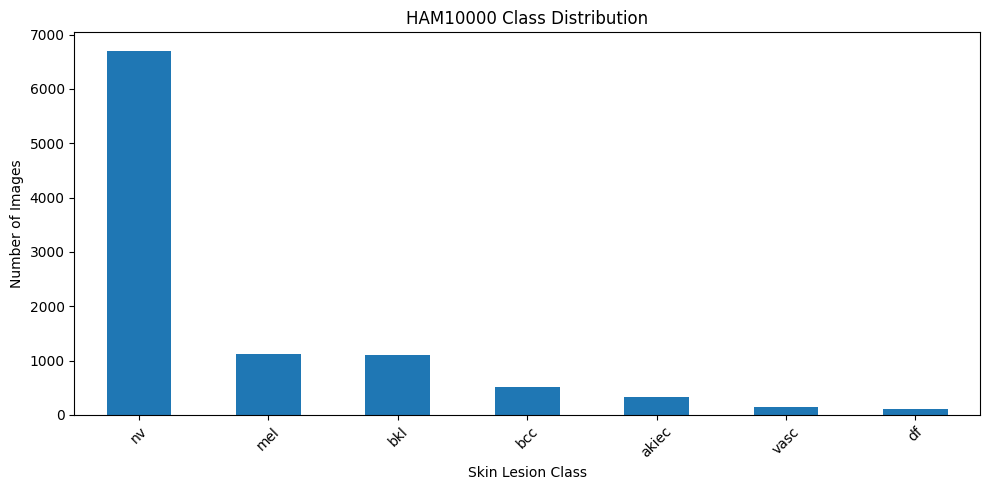

In [ ]:

import matplotlib.pyplot as plt

counts = df["dx"].value_counts()

plt.figure(figsize=(10, 5))
counts.plot(kind="bar")

plt.title("HAM10000 Class Distribution")
plt.xlabel("Skin Lesion Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Missing images: 0


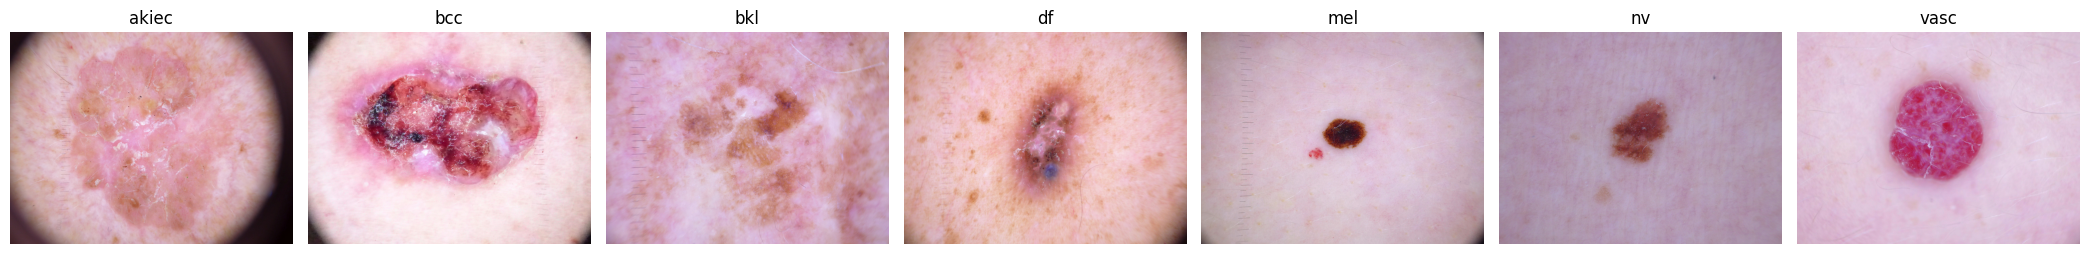

In [ ]:

from PIL import Image
import matplotlib.pyplot as plt

# Build image path mapping
image_map = {
    os.path.splitext(os.path.basename(p))[0]: p
    for p in image_files
}

df["image_path"] = df["image_id"].map(image_map)

missing_images = df["image_path"].isna().sum()
print("Missing images:", missing_images)

if missing_images != 0:
    raise ValueError("Some images are missing. Check dataset copy.")

# Display one image from each class
fig, axes = plt.subplots(1, 7, figsize=(21, 4))

for ax, (label, group) in zip(axes, df.groupby("dx")):
    sample = group.iloc[0]
    img = Image.open(sample["image_path"]).convert("RGB")

    ax.imshow(img)
    ax.set_title(label)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

from sklearn.model_selection import GroupShuffleSplit

# First split: 70% train, 30% temporary
split1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42
)

train_idx, temp_idx = next(
    split1.split(df, groups=df["lesion_id"])
)

train_df = df.iloc[train_idx].copy()
temp_df = df.iloc[temp_idx].copy()

# Second split: 15% validation, 15% test
split2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

val_idx, test_idx = next(
    split2.split(temp_df, groups=temp_df["lesion_id"])
)

val_df = temp_df.iloc[val_idx].copy()
test_df = temp_df.iloc[test_idx].copy()

# Verify no lesion overlaps
assert set(train_df.lesion_id).isdisjoint(val_df.lesion_id)
assert set(train_df.lesion_id).isdisjoint(test_df.lesion_id)
assert set(val_df.lesion_id).isdisjoint(test_df.lesion_id)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

print("\nClass distribution:")
print("Train:", train_df["dx"].value_counts().to_dict())
print("Validation:", val_df["dx"].value_counts().to_dict())
print("Test:", test_df["dx"].value_counts().to_dict())


Training images: 7002
Validation images: 1519
Testing images: 1494

Class distribution:
Train: {'nv': 4718, 'mel': 770, 'bkl': 741, 'bcc': 381, 'akiec': 207, 'vasc': 96, 'df': 89}
Validation: {'nv': 991, 'bkl': 206, 'mel': 156, 'bcc': 65, 'akiec': 57, 'vasc': 25, 'df': 19}
Test: {'nv': 996, 'mel': 187, 'bkl': 152, 'bcc': 68, 'akiec': 63, 'vasc': 21, 'df': 7}


In [ ]:

import os

output_dir = "/content/drive/MyDrive/ID1157_Research/splits"
os.makedirs(output_dir, exist_ok=True)

train_df.to_csv(
    os.path.join(output_dir, "train.csv"),
    index=False
)

val_df.to_csv(
    os.path.join(output_dir, "validation.csv"),
    index=False
)

test_df.to_csv(
    os.path.join(output_dir, "test.csv"),
    index=False
)

print("All split files saved to Google Drive!")


All split files saved to Google Drive!


In [ ]:

import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf

from google.colab import drive

drive.mount('/content/drive')

SEED = 42
tf.keras.utils.set_random_seed(SEED)

BASE = "/content/drive/MyDrive/ID1157_Research"
DATASET = os.path.join(BASE, "HAM10000")
SPLITS = os.path.join(BASE, "splits")
MODELS = os.path.join(BASE, "models")

os.makedirs(MODELS, exist_ok=True)

train_df = pd.read_csv(
    os.path.join(SPLITS, "train.csv")
)
val_df = pd.read_csv(
    os.path.join(SPLITS, "validation.csv")
)
test_df = pd.read_csv(
    os.path.join(SPLITS, "test.csv")
)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))
print("GPU:", tf.config.list_physical_devices("GPU"))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Train: 7002
Validation: 1519
Test: 1494
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:

import glob

image_paths = glob.glob(
    os.path.join(DATASET, "**", "*.jpg"),
    recursive=True
)

image_map = {
    os.path.splitext(os.path.basename(p))[0]: p
    for p in image_paths
}

for data in [train_df, val_df, test_df]:
    data["image_path"] = data["image_id"].map(image_map)

    assert data["image_path"].notna().all(), \
        "Some image files are missing!"

classes = sorted(train_df["dx"].unique())

assert set(val_df["dx"]).issubset(classes)
assert set(test_df["dx"]).issubset(classes)
assert len(classes) == 7

class_to_idx = {
    name: i for i, name in enumerate(classes)
}

for data in [train_df, val_df, test_df]:
    data["label"] = data["dx"].map(class_to_idx)

print("Classes:", classes)
print("All image paths verified!")


Classes: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
All image paths verified!


In [ ]:

IMG_SIZE = (224, 224)
BATCH_SIZE = 16
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(
        image, channels=3
    )

    image = tf.image.resize(
        image, IMG_SIZE
    )

    image = tf.cast(image, tf.float32)

    # MobileNetV2 preprocessing: [-1, 1]
    image = tf.keras.applications.mobilenet_v2.preprocess_input(
        image
    )

    return image, label

def make_dataset(dataframe, training=False):
    paths = dataframe["image_path"].values
    labels = dataframe["label"].astype("int32").values

    ds = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        ds = ds.shuffle(
            len(dataframe),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    ds = ds.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(AUTOTUNE)

    return ds

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

print("Preprocessing completed!")

for images, labels in train_ds.take(1):
    print("Image shape:", images.shape)
    print("Labels shape:", labels.shape)


Preprocessing completed!
Image shape: (16, 224, 224, 3)
Labels shape: (16,)


In [ ]:

from tensorflow.keras import layers, Model

# Load pretrained MobileNetV2
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze pretrained layers
base_model.trainable = False

# Data augmentation
augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
], name="data_augmentation")

# Build classification model
inputs = layers.Input(shape=(224, 224, 3))

x = augmentation(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    len(classes),
    activation="softmax"
)(x)

model = Model(inputs, outputs)

# Compile model
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

print("MobileNetV2 Model Ready!")


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 7)              │         8,967 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,266,951 (8.65 MB)

 Trainable params: 8,967 (35.03 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

MobileNetV2 Model Ready!


In [ ]:

from tensorflow.keras.callbacks import (
    ModelCheckpoint,
    EarlyStopping,
    CSVLogger
)

import os

model_dir = "/content/drive/MyDrive/ID1157_Research/models"
os.makedirs(model_dir, exist_ok=True)

checkpoint_path = os.path.join(
    model_dir,
    "mobilenetv2_best.keras"
)

callbacks = [
    ModelCheckpoint(
        checkpoint_path,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    CSVLogger(
        os.path.join(
            model_dir,
            "mobilenetv2_training_log.csv"
        ),
        append=False
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks
)

print("MobileNetV2 Training Completed!")
print("Saved Model:", checkpoint_path)


Epoch 1/10
438/438 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.4983 - loss: 1.5582
Epoch 1: val_loss improved from None to 0.99207, saving model to /content/drive/MyDrive/ID1157_Research/models/mobilenetv2_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/ID1157_Research/models/mobilenetv2_best.keras
438/438 ━━━━━━━━━━━━━━━━━━━━ 1813s 4s/step - accuracy: 0.5935 - loss: 1.2893 - val_accuracy: 0.6722 - val_loss: 0.9921
Epoch 2/10
437/438 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step - accuracy: 0.6529 - loss: 1.0465
Epoch 2: val_loss improved from 0.99207 to 0.89532, saving model to /content/drive/MyDrive/ID1157_Research/models/mobilenetv2_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/ID1157_Research/models/mobilenetv2_best.keras
438/438 ━━━━━━━━━━━━━━━━━━━━ 51s 115ms/step - accuracy: 0.6660 - loss: 1.0093 - val_accuracy: 0.6801 - val_loss: 0.8953
Epoch 3/10
438/438 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step - accuracy: 0.6950 - loss: 0.9181
Epoch 3: val_loss impro

In [ ]:

import os
import tensorflow as tf

print("=== ID 1157 Training Check ===")

# Check GPU
print("GPU:", tf.config.list_physical_devices("GPU"))

# Check datasets
print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())

# Check model
print("Model output:", model.output_shape)
print("Model compiled:", model.optimizer is not None)

# Check saved model
checkpoint_path = "/content/drive/MyDrive/ID1157_Research/models/mobilenetv2_best.keras"

print("Previous checkpoint exists:",
      os.path.isfile(checkpoint_path))

print("Readiness check completed!")


=== ID 1157 Training Check ===
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Training batches: 438
Validation batches: 95
Model output: (None, 7)
Model compiled: True
Previous checkpoint exists: True
Readiness check completed!


In [ ]:

if os.path.isfile(checkpoint_path):
    saved_model = tf.keras.models.load_model(
        checkpoint_path
    )

    print("Saved model loaded successfully!")
    print("Output shape:", saved_model.output_shape)
else:
    print("No previous saved model found.")


Saved model loaded successfully!
Output shape: (None, 7)


In [ ]:

import os
import pandas as pd

log_path = "/content/drive/MyDrive/ID1157_Research/models/mobilenetv2_training_log.csv"

if os.path.exists(log_path):
    log_df = pd.read_csv(log_path)

    print("=== ID 1157 Training History ===")
    print("Completed epochs:", len(log_df))

    display(log_df)

    if len(log_df) > 0:
        print("\nBest Validation Accuracy:",
              log_df["val_accuracy"].max())

        print("Best Validation Loss:",
              log_df["val_loss"].min())
else:
    print("Training log not found.")


=== ID 1157 Training History ===
Completed epochs: 10


,epoch,accuracy,loss,val_accuracy,val_loss
0,0,0.593545,1.289323,0.672153,0.992070
1,1,0.665953,1.009288,0.680053,0.895318
2,2,0.693373,0.912953,0.695194,0.851294
3,3,0.704656,0.873922,0.707044,0.827800
4,4,0.706084,0.837012,0.720211,0.802911
5,5,0.713510,0.816650,0.720211,0.800378
6,6,0.719509,0.792883,0.708361,0.795439
7,7,0.727649,0.782948,0.725477,0.769706
8,8,0.725364,0.768276,0.727452,0.777612
9,9,0.730220,0.746603,0.730744,0.758674



Best Validation Accuracy: 0.7307438850402832
Best Validation Loss: 0.7586743831634521


In [ ]:

import tensorflow as tf

checkpoint_path = "/content/drive/MyDrive/ID1157_Research/models/mobilenetv2_best.keras"

# Load best saved MobileNetV2 model
best_model = tf.keras.models.load_model(checkpoint_path)

print("=== ID 1157 MobileNetV2 Test Evaluation ===")

test_loss, test_accuracy = best_model.evaluate(
    test_ds,
    verbose=1
)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")


=== ID 1157 MobileNetV2 Test Evaluation ===
94/94 ━━━━━━━━━━━━━━━━━━━━ 334s 4s/step - accuracy: 0.7410 - loss: 0.7470
Test Accuracy: 74.10%
Test Loss: 0.7470


=== ID 1157 MobileNetV2 Classification Report ===
94/94 ━━━━━━━━━━━━━━━━━━━━ 12s 109ms/step
              precision    recall  f1-score   support

       akiec       0.70      0.11      0.19        63
         bcc       0.51      0.37      0.43        68
         bkl       0.43      0.49      0.46       152
          df       0.00      0.00      0.00         7
         mel       0.49      0.26      0.34       187
          nv       0.82      0.94      0.88       996
        vasc       0.72      0.62      0.67        21

    accuracy                           0.74      1494
   macro avg       0.53      0.40      0.42      1494
weighted avg       0.72      0.74      0.71      1494

Test Accuracy: 0.7409638554216867
Macro F1-Score: 0.4230000113554719
Weighted F1-Score: 0.7109029251308119


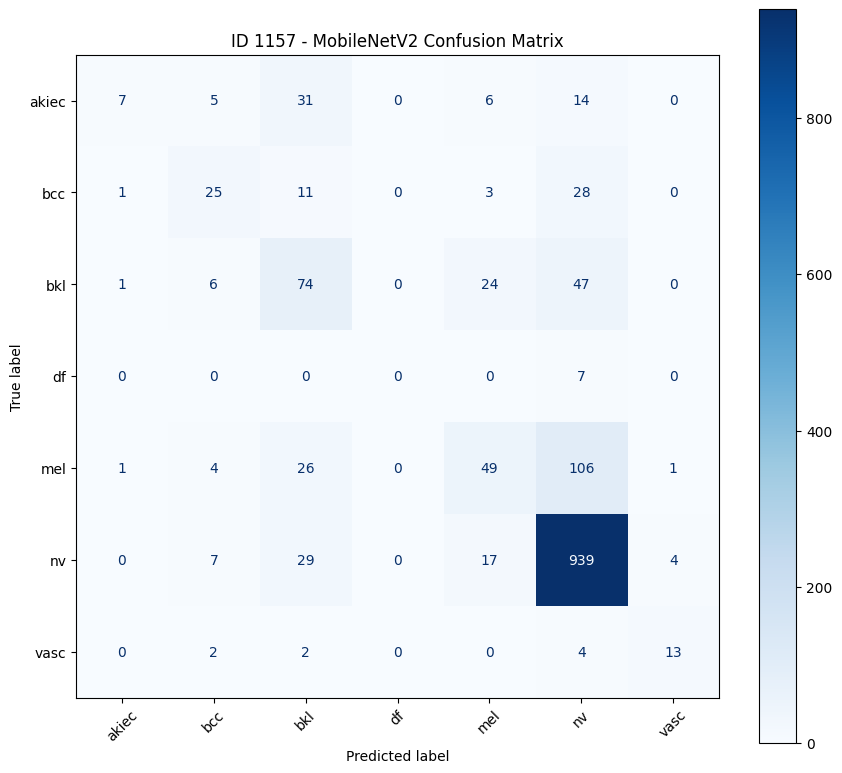

Confusion Matrix Saved Successfully!


In [ ]:

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    f1_score
)

print("=== ID 1157 MobileNetV2 Classification Report ===")

# Get predictions from best saved model
y_prob = best_model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

# Get true labels in dataset order
y_true = np.concatenate([
    y.numpy() for x, y in test_ds
])

# Classification report
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(classes))),
    target_names=classes,
    zero_division=0
))

# Overall metrics
print("Test Accuracy:",
      accuracy_score(y_true, y_pred))

print("Macro F1-Score:",
      f1_score(y_true, y_pred, average="macro"))

print("Weighted F1-Score:",
      f1_score(y_true, y_pred, average="weighted"))

# Confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(classes)))
)

fig, ax = plt.subplots(figsize=(9, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)

disp.plot(ax=ax, cmap="Blues", values_format="d")
plt.title("ID 1157 - MobileNetV2 Confusion Matrix")
plt.xticks(rotation=45)
plt.tight_layout()

# Save confusion matrix to Google Drive
results_dir = "/content/drive/MyDrive/ID1157_Research/results"
import os
os.makedirs(results_dir, exist_ok=True)

plt.savefig(
    os.path.join(results_dir, "mobilenetv2_confusion_matrix.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion Matrix Saved Successfully!")


In [ ]:

import os

print("Drive mounted:",
      os.path.ismount("/content/drive"))

print("Drive folder exists:",
      os.path.isdir("/content/drive"))

print("Drive contents:")
print(os.listdir("/content/drive"))

model_path = "/content/drive/MyDrive/ID1157_Research/models/mobilenetv2_best.keras"

print("Saved model exists:",
      os.path.isfile(model_path))


Drive mounted: False
Drive folder exists: True
Drive contents:
['MyDrive']
Saved model exists: False


In [ ]:

from google.colab import drive
import os

# Create a new empty mount location
new_mount = "/content/gdrive1157"

os.makedirs(new_mount, exist_ok=True)

# Mount Google Drive
drive.mount(new_mount)

print("Drive mounted successfully!")

# Check saved model
model_path = (
    "/content/gdrive1157/MyDrive/"
    "ID1157_Research/models/mobilenetv2_best.keras"
)

print("Saved model exists:", os.path.isfile(model_path))


Mounted at /content/gdrive1157
Drive mounted successfully!
Saved model exists: True


In [ ]:

import tensorflow as tf
import os

BASE = "/content/gdrive1157/MyDrive/ID1157_Research"

model_path = os.path.join(
    BASE, "models", "mobilenetv2_best.keras"
)

best_model = tf.keras.models.load_model(model_path)

print("ID 1157: MobileNetV2 Loaded Successfully!")
print("Model Output:", best_model.output_shape)


ID 1157: MobileNetV2 Loaded Successfully!
Model Output: (None, 7)


In [ ]:

print("=== ID 1157 Dataset Check ===")

for name in ["test_ds", "classes", "test_df"]:
    print(name, "Available:", name in globals())


=== ID 1157 Dataset Check ===
test_ds Available: False
classes Available: False
test_df Available: False


In [ ]:

import os
import glob
import pandas as pd
import tensorflow as tf

BASE = "/content/gdrive1157/MyDrive/ID1157_Research"
DATASET = os.path.join(BASE, "HAM10000")
SPLITS = os.path.join(BASE, "splits")

# Load saved test split
test_df = pd.read_csv(
    os.path.join(SPLITS, "test.csv")
)

# Restore seven class labels from saved splits
train_df = pd.read_csv(os.path.join(SPLITS, "train.csv"))
val_df = pd.read_csv(os.path.join(SPLITS, "validation.csv"))

classes = sorted(
    pd.concat([
        train_df["dx"],
        val_df["dx"],
        test_df["dx"]
    ]).unique().tolist()
)

class_to_idx = {
    name: idx for idx, name in enumerate(classes)
}

# Find images in Google Drive
image_files = glob.glob(
    os.path.join(DATASET, "**", "*.jpg"),
    recursive=True
)

image_map = {
    os.path.splitext(os.path.basename(p))[0]: p
    for p in image_files
}

test_df["image_path"] = test_df["image_id"].map(image_map)

assert test_df["image_path"].notna().all(), \
    "Some test images were not found!"

print("Classes:", classes)
print("Test images:", len(test_df))
print("Images found:", len(image_files))

# Restore preprocessing
IMG_SIZE = (224, 224)
BATCH_SIZE = 16

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.keras.applications.mobilenet_v2.preprocess_input(image)
    return image, label

test_paths = test_df["image_path"].astype(str).values
test_labels = test_df["dx"].map(class_to_idx).astype("int32").values

test_ds = tf.data.Dataset.from_tensor_slices(
    (test_paths, test_labels)
)

test_ds = test_ds.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

# Important: no shuffle for evaluation
test_ds = test_ds.batch(BATCH_SIZE).prefetch(
    tf.data.AUTOTUNE
)

print("Test Dataset Restored Successfully!")
print("Test batches:",
      tf.data.experimental.cardinality(test_ds).numpy())


Classes: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
Test images: 1494
Images found: 20030
Test Dataset Restored Successfully!
Test batches: 94


In [ ]:

print("=== ID 1157 Restore Check ===")

print("Model loaded:", best_model is not None)
print("Test dataset:", test_ds is not None)
print("Number of classes:", len(classes))
print("Test image count:", len(test_df))
print("Missing images:", test_df["image_path"].isna().sum())


=== ID 1157 Restore Check ===
Model loaded: True
Test dataset: True
Number of classes: 7
Test image count: 1494
Missing images: 0


Generating MobileNetV2 predictions...
94/94 ━━━━━━━━━━━━━━━━━━━━ 308s 3s/step

=== ID 1157 MobileNetV2 Results ===
Test Accuracy: 74.10%
Macro F1-Score: 0.4230
Weighted F1-Score: 0.7109


,precision,recall,f1-score,support
akiec,0.7000,0.1111,0.1918,63.000
bcc,0.5102,0.3676,0.4274,68.000
bkl,0.4277,0.4868,0.4554,152.000
df,0.0000,0.0000,0.0000,7.000
mel,0.4949,0.2620,0.3427,187.000
nv,0.8201,0.9428,0.8772,996.000
vasc,0.7222,0.6190,0.6667,21.000
accuracy,0.7410,0.7410,0.7410,0.741
macro avg,0.5250,0.3985,0.4230,1494.000
weighted avg,0.7151,0.7410,0.7109,1494.000


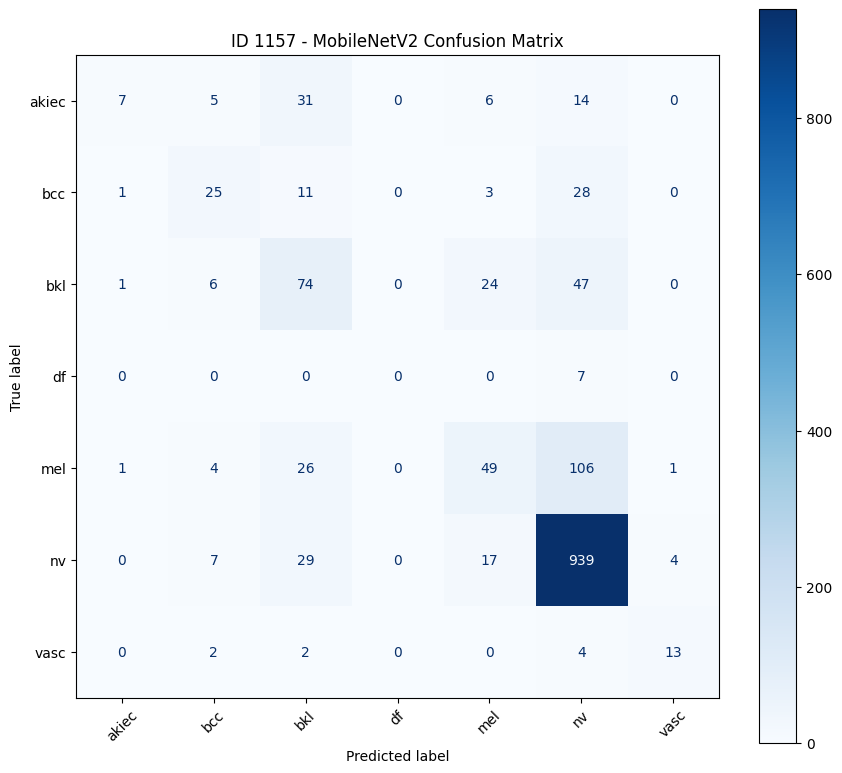


All MobileNetV2 results saved successfully!
Results folder: /content/gdrive1157/MyDrive/ID1157_Research/results


In [ ]:

import os
import numpy as np
import pandas as pd

from sklearn.metrics import (
    classification_report,
    accuracy_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Project results folder
results_dir = os.path.join(BASE, "results")
os.makedirs(results_dir, exist_ok=True)

# Predict with saved model
print("Generating MobileNetV2 predictions...")
y_prob = best_model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

# True labels in the same order
y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

assert len(y_true) == len(y_pred), "Prediction count mismatch!"

# Calculate metrics
test_accuracy = accuracy_score(y_true, y_pred)
macro_f1 = f1_score(y_true, y_pred, average="macro")
weighted_f1 = f1_score(y_true, y_pred, average="weighted")

print("\n=== ID 1157 MobileNetV2 Results ===")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Macro F1-Score: {macro_f1:.4f}")
print(f"Weighted F1-Score: {weighted_f1:.4f}")

# Classification report
report = classification_report(
    y_true,
    y_pred,
    labels=list(range(len(classes))),
    target_names=classes,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()
display(report_df.round(4))

# Save classification report
report_df.to_csv(
    os.path.join(
        results_dir,
        "mobilenetv2_classification_report.csv"
    )
)

# Save summary metrics
summary_df = pd.DataFrame([{
    "model": "MobileNetV2",
    "test_accuracy": test_accuracy,
    "macro_f1": macro_f1,
    "weighted_f1": weighted_f1
}])

summary_df.to_csv(
    os.path.join(
        results_dir,
        "mobilenetv2_metrics.csv"
    ),
    index=False
)

# Confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(classes)))
)

fig, ax = plt.subplots(figsize=(9, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)

disp.plot(ax=ax, cmap="Blues", values_format="d")
plt.title("ID 1157 - MobileNetV2 Confusion Matrix")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    os.path.join(
        results_dir,
        "mobilenetv2_confusion_matrix.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nAll MobileNetV2 results saved successfully!")
print("Results folder:", results_dir)


In [ ]:

import os
import glob
import pandas as pd
import tensorflow as tf

print("=== ID 1157: ResNet50 Dataset Preparation ===")

BASE = "/content/gdrive1157/MyDrive/ID1157_Research"
DATASET = os.path.join(BASE, "HAM10000")
SPLITS = os.path.join(BASE, "splits")

# Load existing dataset splits
train_df = pd.read_csv(os.path.join(SPLITS, "train.csv"))
val_df = pd.read_csv(os.path.join(SPLITS, "validation.csv"))
test_df = pd.read_csv(os.path.join(SPLITS, "test.csv"))

# Restore class mapping
classes = sorted(
    pd.concat([
        train_df["dx"],
        val_df["dx"],
        test_df["dx"]
    ]).unique()
)

class_to_idx = {
    label: idx for idx, label in enumerate(classes)
}

# Find image files
image_files = glob.glob(
    os.path.join(DATASET, "**", "*.jpg"),
    recursive=True
)

image_map = {
    os.path.splitext(os.path.basename(path))[0]: path
    for path in image_files
}

# Restore image paths
for df in [train_df, val_df, test_df]:
    df["image_path"] = df["image_id"].map(image_map)
    assert df["image_path"].notna().all(), \
        "Some image paths are missing!"

# ResNet50 image preprocessing
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
SEED = 42

def load_resnet_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)

    image = tf.keras.applications.resnet50.preprocess_input(image)

    return image, label

def make_resnet_dataset(df, shuffle=False):
    paths = df["image_path"].astype(str).values
    labels = df["dx"].map(class_to_idx).astype("int32").values

    ds = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if shuffle:
        ds = ds.shuffle(
            buffer_size=len(df),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    ds = ds.map(
        load_resnet_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

# Create ResNet50 datasets
resnet_train_ds = make_resnet_dataset(train_df, shuffle=True)
resnet_val_ds = make_resnet_dataset(val_df, shuffle=False)
resnet_test_ds = make_resnet_dataset(test_df, shuffle=False)

print("Classes:", list(classes))
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))

print("Training batches:",
      tf.data.experimental.cardinality(resnet_train_ds).numpy())
print("Validation batches:",
      tf.data.experimental.cardinality(resnet_val_ds).numpy())
print("Test batches:",
      tf.data.experimental.cardinality(resnet_test_ds).numpy())

print("ResNet50 Dataset Ready!")


=== ID 1157: ResNet50 Dataset Preparation ===
Classes: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
Training images: 7002
Validation images: 1519
Test images: 1494
Training batches: 438
Validation batches: 95
Test batches: 94
ResNet50 Dataset Ready!


In [ ]:

import tensorflow as tf
from tensorflow.keras import layers, Model

print("=== ID 1157: Building ResNet50 ===")

# Load pretrained ResNet50
resnet_base = tf.keras.applications.ResNet50(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze pretrained layers
resnet_base.trainable = False

# Data augmentation
resnet_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
], name="resnet_augmentation")

# Build classification model
inputs = layers.Input(shape=(224, 224, 3))

x = resnet_augmentation(inputs)
x = resnet_base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    len(classes),
    activation="softmax"
)(x)

resnet_model = Model(
    inputs=inputs,
    outputs=outputs,
    name="ID1157_ResNet50"
)

# Compile model
resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

resnet_model.summary()

print("ID 1157: ResNet50 Model Ready!")


=== ID 1157: Building ResNet50 ===
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "ID1157_ResNet50"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet_augmentation             │ (None, 224, 224, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 7)              │        14,343 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,602,055 (90.03 MB)

 Trainable params: 14,343 (56.03 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

ID 1157: ResNet50 Model Ready!


In [ ]:

import os
import tensorflow as tf

from tensorflow.keras.callbacks import (
    ModelCheckpoint,
    EarlyStopping,
    CSVLogger
)

print("=== ID 1157: ResNet50 Training ===")

# Google Drive model directory
model_dir = os.path.join(BASE, "models")
os.makedirs(model_dir, exist_ok=True)

# Separate checkpoint for ResNet50
resnet_checkpoint = os.path.join(
    model_dir,
    "resnet50_best.keras"
)

resnet_log = os.path.join(
    model_dir,
    "resnet50_training_log.csv"
)

# Training callbacks
resnet_callbacks = [
    ModelCheckpoint(
        resnet_checkpoint,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    CSVLogger(
        resnet_log,
        append=False
    )
]

# Train ResNet50
resnet_history = resnet_model.fit(
    resnet_train_ds,
    validation_data=resnet_val_ds,
    epochs=10,
    callbacks=resnet_callbacks
)

print("\nResNet50 Training Completed!")
print("Saved Model:", resnet_checkpoint)
print("Training Log:", resnet_log)


=== ID 1157: ResNet50 Training ===
Epoch 1/10
438/438 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.4833 - loss: 1.6782
Epoch 1: val_loss improved from None to 0.95749, saving model to /content/gdrive1157/MyDrive/ID1157_Research/models/resnet50_best.keras

Epoch 1: finished saving model to /content/gdrive1157/MyDrive/ID1157_Research/models/resnet50_best.keras
438/438 ━━━━━━━━━━━━━━━━━━━━ 1769s 4s/step - accuracy: 0.5937 - loss: 1.3207 - val_accuracy: 0.6801 - val_loss: 0.9575
Epoch 2/10
438/438 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step - accuracy: 0.6664 - loss: 0.9775
Epoch 2: val_loss improved from 0.95749 to 0.81602, saving model to /content/gdrive1157/MyDrive/ID1157_Research/models/resnet50_best.keras

Epoch 2: finished saving model to /content/gdrive1157/MyDrive/ID1157_Research/models/resnet50_best.keras
438/438 ━━━━━━━━━━━━━━━━━━━━ 73s 167ms/step - accuracy: 0.6788 - loss: 0.9531 - val_accuracy: 0.6978 - val_loss: 0.8160
Epoch 3/10
438/438 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step - accuracy: 

In [ ]:

from google.colab import drive
import os

mount_path = "/content/drive1157_new"
os.makedirs(mount_path, exist_ok=True)

drive.mount(mount_path)

print("Google Drive Mounted!")


Mounted at /content/drive1157_new
Google Drive Mounted!


In [ ]:

import os
import glob

BASE = "/content/drive1157_new/MyDrive/ID1157_Research"

print("Research folder exists:", os.path.isdir(BASE))

model_dir = os.path.join(BASE, "models")

print("Models folder exists:", os.path.isdir(model_dir))

if os.path.isdir(model_dir):
    print("\nSaved model files:")
    for file in os.listdir(model_dir):
        print(file)

model_path = os.path.join(
    model_dir, "resnet50_best.keras"
)

print("\nResNet50 model found:", os.path.isfile(model_path))


Research folder exists: True
Models folder exists: True

Saved model files:
mobilenetv2_training_log.csv
mobilenetv2_best.keras
resnet50_training_log.csv
resnet50_best.keras

ResNet50 model found: True


In [ ]:

import os
import tensorflow as tf

BASE = "/content/drive1157_new/MyDrive/ID1157_Research"

model_path = os.path.join(
    BASE, "models", "resnet50_best.keras"
)

# Load saved ResNet50 model
resnet_best_model = tf.keras.models.load_model(
    model_path
)

print("ResNet50 Model Loaded Successfully!")
print("Model Output:", resnet_best_model.output_shape)

# Check test dataset
print(
    "ResNet50 Test Dataset Available:",
    "resnet_test_ds" in globals()
)


ResNet50 Model Loaded Successfully!
Model Output: (None, 7)
ResNet50 Test Dataset Available: False


In [ ]:

import os
import glob
import pandas as pd
import tensorflow as tf

BASE = "/content/drive1157_new/MyDrive/ID1157_Research"
DATASET = os.path.join(BASE, "HAM10000")
SPLITS = os.path.join(BASE, "splits")

# Load original test split
test_df = pd.read_csv(
    os.path.join(SPLITS, "test.csv")
)

# Restore original class order
train_df = pd.read_csv(
    os.path.join(SPLITS, "train.csv")
)
val_df = pd.read_csv(
    os.path.join(SPLITS, "validation.csv")
)

classes = sorted(
    pd.concat([
        train_df["dx"],
        val_df["dx"],
        test_df["dx"]
    ]).unique().tolist()
)

class_to_idx = {
    label: i for i, label in enumerate(classes)
}

# Find original images
image_files = glob.glob(
    os.path.join(DATASET, "**", "*.jpg"),
    recursive=True
)

image_map = {
    os.path.splitext(os.path.basename(p))[0]: p
    for p in image_files
}

test_df["image_path"] = test_df["image_id"].map(image_map)

assert test_df["image_path"].notna().all(), \
    "Some test images are missing!"

# ResNet50-specific preprocessing
def load_resnet_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, (224, 224))
    image = tf.keras.applications.resnet50.preprocess_input(
        image
    )
    return image, label

test_paths = test_df["image_path"].astype(str).values
test_labels = test_df["dx"].map(
    class_to_idx
).astype("int32").values

resnet_test_ds = tf.data.Dataset.from_tensor_slices(
    (test_paths, test_labels)
)

resnet_test_ds = resnet_test_ds.map(
    load_resnet_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

# No shuffle during evaluation
resnet_test_ds = resnet_test_ds.batch(16).prefetch(
    tf.data.AUTOTUNE
)

print("ResNet50 Test Dataset Restored!")
print("Classes:", classes)
print("Test images:", len(test_df))
print("Missing images:", test_df["image_path"].isna().sum())
print("Test batches:",
      tf.data.experimental.cardinality(
          resnet_test_ds
      ).numpy())


ResNet50 Test Dataset Restored!
Classes: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
Test images: 1494
Missing images: 0
Test batches: 94


In [ ]:

print("=== ID 1157 ResNet50 Test Evaluation ===")

test_loss, test_accuracy = resnet_best_model.evaluate(
    resnet_test_ds,
    verbose=1
)

print(f"ResNet50 Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"ResNet50 Test Loss: {test_loss:.4f}")


=== ID 1157 ResNet50 Test Evaluation ===
94/94 ━━━━━━━━━━━━━━━━━━━━ 262s 3s/step - accuracy: 0.7751 - loss: 0.6443
ResNet50 Test Accuracy: 77.51%
ResNet50 Test Loss: 0.6443


=== ID 1157 ResNet50 Classification Report ===
94/94 ━━━━━━━━━━━━━━━━━━━━ 18s 151ms/step

Classification Report:


,precision,recall,f1-score,support
akiec,0.8000,0.1270,0.2192,63.0000
bcc,0.6512,0.4118,0.5045,68.0000
bkl,0.4971,0.5592,0.5263,152.0000
df,0.0000,0.0000,0.0000,7.0000
mel,0.5443,0.4599,0.4986,187.0000
nv,0.8552,0.9488,0.8996,996.0000
vasc,1.0000,0.2857,0.4444,21.0000
accuracy,0.7751,0.7751,0.7751,0.7751
macro avg,0.6211,0.3989,0.4418,1494.0000
weighted avg,0.7663,0.7751,0.7541,1494.0000


Test Accuracy: 0.7751004016064257
Macro F1: 0.4417950254011459
Weighted F1: 0.7541165932735411


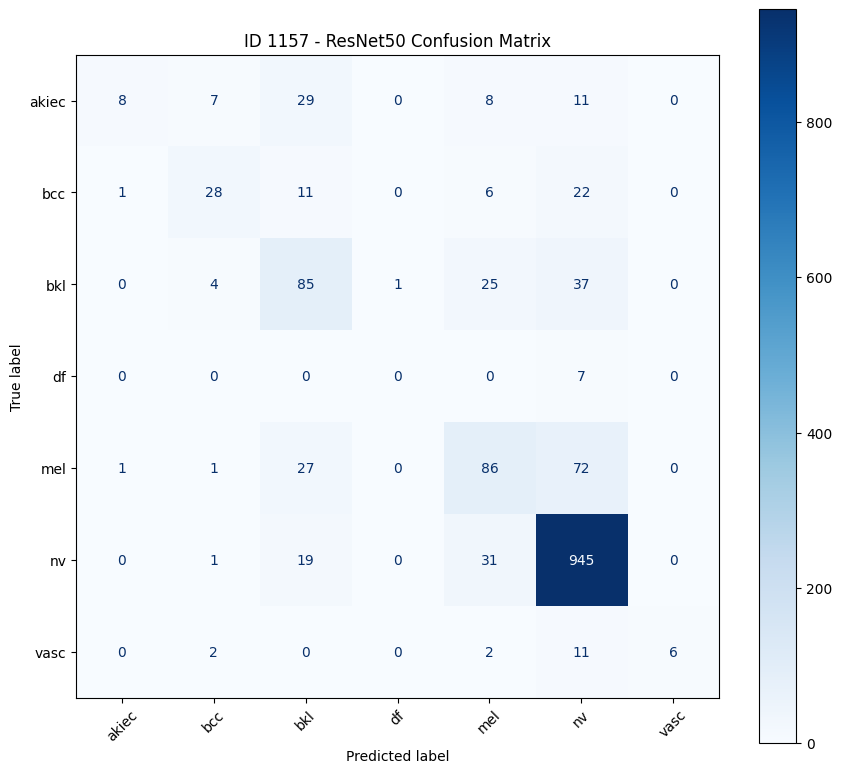

ResNet50 Results Saved Successfully!


In [ ]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    f1_score
)

print("=== ID 1157 ResNet50 Classification Report ===")

# Generate predictions
y_prob_resnet = resnet_best_model.predict(
    resnet_test_ds,
    verbose=1
)

y_pred_resnet = np.argmax(y_prob_resnet, axis=1)

# Actual labels in matching order
y_true_resnet = np.concatenate([
    labels.numpy()
    for images, labels in resnet_test_ds
])

assert len(y_true_resnet) == len(y_pred_resnet)

# Calculate classification metrics
report = classification_report(
    y_true_resnet,
    y_pred_resnet,
    labels=list(range(len(classes))),
    target_names=classes,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

print("\nClassification Report:")
display(report_df.round(4))

print("Test Accuracy:",
      accuracy_score(y_true_resnet, y_pred_resnet))

print("Macro F1:",
      f1_score(y_true_resnet, y_pred_resnet, average="macro"))

print("Weighted F1:",
      f1_score(y_true_resnet, y_pred_resnet, average="weighted"))

# Save results
results_dir = os.path.join(BASE, "results")
os.makedirs(results_dir, exist_ok=True)

report_df.to_csv(
    os.path.join(
        results_dir,
        "resnet50_classification_report.csv"
    )
)

# Confusion matrix
cm = confusion_matrix(
    y_true_resnet,
    y_pred_resnet,
    labels=list(range(len(classes)))
)

fig, ax = plt.subplots(figsize=(9, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)

disp.plot(ax=ax, cmap="Blues", values_format="d")

plt.title("ID 1157 - ResNet50 Confusion Matrix")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    os.path.join(
        results_dir,
        "resnet50_confusion_matrix.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("ResNet50 Results Saved Successfully!")


In [ ]:

import os
import glob
import pandas as pd
import tensorflow as tf

print("=== ID 1157: EfficientNetB0 Dataset Preparation ===")

# Google Drive project location
BASE = "/content/drive1157_new/MyDrive/ID1157_Research"
DATASET = os.path.join(BASE, "HAM10000")
SPLITS = os.path.join(BASE, "splits")

# Check required folders
assert os.path.isdir(DATASET), "Dataset folder not found!"
assert os.path.isdir(SPLITS), "Splits folder not found!"

# Load the SAME saved dataset splits
train_df = pd.read_csv(
    os.path.join(SPLITS, "train.csv")
)
val_df = pd.read_csv(
    os.path.join(SPLITS, "validation.csv")
)
test_df = pd.read_csv(
    os.path.join(SPLITS, "test.csv")
)

# Restore class order
classes = sorted(
    pd.concat([
        train_df["dx"],
        val_df["dx"],
        test_df["dx"]
    ]).unique().tolist()
)

class_to_idx = {
    label: i for i, label in enumerate(classes)
}

# Find image files
image_files = glob.glob(
    os.path.join(DATASET, "**", "*.jpg"),
    recursive=True
)

image_map = {
    os.path.splitext(os.path.basename(path))[0]: path
    for path in image_files
}

# Match image IDs to file paths
for df in [train_df, val_df, test_df]:
    df["image_path"] = df["image_id"].map(image_map)

    assert df["image_path"].notna().all(), \
        "Some image paths are missing!"

# Image settings
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
SEED = 42

# EfficientNetB0 expects image values in 0-255 range
def load_efficientnet_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)

    # Do NOT divide by 255
    # Do NOT use MobileNetV2/ResNet50 preprocessing
    return image, label

def make_efficientnet_dataset(df, shuffle=False):
    paths = df["image_path"].astype(str).values
    labels = df["dx"].map(
        class_to_idx
    ).astype("int32").values

    ds = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if shuffle:
        ds = ds.shuffle(
            buffer_size=len(df),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    ds = ds.map(
        load_efficientnet_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(tf.data.AUTOTUNE)

    return ds

# Build datasets
efficient_train_ds = make_efficientnet_dataset(
    train_df, shuffle=True
)

efficient_val_ds = make_efficientnet_dataset(
    val_df, shuffle=False
)

efficient_test_ds = make_efficientnet_dataset(
    test_df, shuffle=False
)

# Verify datasets
print("\nClasses:", classes)
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))

print("\nTraining batches:",
      tf.data.experimental.cardinality(
          efficient_train_ds
      ).numpy())

print("Validation batches:",
      tf.data.experimental.cardinality(
          efficient_val_ds
      ).numpy())

print("Test batches:",
      tf.data.experimental.cardinality(
          efficient_test_ds
      ).numpy())

print("\nID 1157: EfficientNetB0 Dataset Ready!")


=== ID 1157: EfficientNetB0 Dataset Preparation ===

Classes: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
Training images: 7002
Validation images: 1519
Test images: 1494

Training batches: 438
Validation batches: 95
Test batches: 94

ID 1157: EfficientNetB0 Dataset Ready!


In [ ]:

import tensorflow as tf
from tensorflow.keras import layers, Model

print("=== ID 1157: Building EfficientNetB0 ===")

# Reproducibility
tf.keras.utils.set_random_seed(42)

# Load ImageNet pretrained EfficientNetB0
efficient_base = tf.keras.applications.EfficientNetB0(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze pretrained layers
efficient_base.trainable = False

# Data augmentation on raw RGB images
efficient_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
], name="efficientnet_augmentation")

# Build model
inputs = layers.Input(shape=(224, 224, 3))

x = efficient_augmentation(inputs)
x = efficient_base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    len(classes),
    activation="softmax"
)(x)

efficient_model = Model(
    inputs=inputs,
    outputs=outputs,
    name="ID1157_EfficientNetB0"
)

# Compile
efficient_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Verify model
efficient_model.summary()

print("\nModel output:", efficient_model.output_shape)
print("Model compiled:", efficient_model.optimizer is not None)
print("ID 1157: EfficientNetB0 Model Ready!")


=== ID 1157: Building EfficientNetB0 ===
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "ID1157_EfficientNetB0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnet_augmentation       │ (None, 224, 224, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 7)              │         8,967 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,058,538 (15.48 MB)

 Trainable params: 8,967 (35.03 KB)

 Non-trainable params: 4,049,571 (15.45 MB)


Model output: (None, 7)
Model compiled: True
ID 1157: EfficientNetB0 Model Ready!


In [ ]:

import os
import tensorflow as tf

from tensorflow.keras.callbacks import (
    ModelCheckpoint,
    EarlyStopping,
    CSVLogger
)

print("=== ID 1157: EfficientNetB0 Training ===")

# Save directory
model_dir = os.path.join(BASE, "models")
os.makedirs(model_dir, exist_ok=True)

# Separate files for EfficientNetB0
efficient_checkpoint = os.path.join(
    model_dir,
    "efficientnetb0_best.keras"
)

efficient_log = os.path.join(
    model_dir,
    "efficientnetb0_training_log.csv"
)

# Safety checks
assert "efficient_model" in globals(), "Run Step 9.2 first!"
assert "efficient_train_ds" in globals(), "Run Step 9.1 first!"
assert "efficient_val_ds" in globals(), "Run Step 9.1 first!"

print("Checkpoint:", efficient_checkpoint)
print("Training log:", efficient_log)

# Callbacks
efficient_callbacks = [
    ModelCheckpoint(
        filepath=efficient_checkpoint,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    CSVLogger(
        filename=efficient_log,
        append=False
    )
]

# Train model
efficient_history = efficient_model.fit(
    efficient_train_ds,
    validation_data=efficient_val_ds,
    epochs=10,
    callbacks=efficient_callbacks
)

print("\nID 1157: EfficientNetB0 Training Completed!")
print("Saved Model:", efficient_checkpoint)
print("Training Log:", efficient_log)


=== ID 1157: EfficientNetB0 Training ===
Checkpoint: /content/drive1157_new/MyDrive/ID1157_Research/models/efficientnetb0_best.keras
Training log: /content/drive1157_new/MyDrive/ID1157_Research/models/efficientnetb0_training_log.csv
Epoch 1/10
438/438 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.5835 - loss: 1.3094
Epoch 1: val_loss improved from None to 1.01642, saving model to /content/drive1157_new/MyDrive/ID1157_Research/models/efficientnetb0_best.keras

Epoch 1: finished saving model to /content/drive1157_new/MyDrive/ID1157_Research/models/efficientnetb0_best.keras
438/438 ━━━━━━━━━━━━━━━━━━━━ 712s 2s/step - accuracy: 0.6440 - loss: 1.1401 - val_accuracy: 0.6485 - val_loss: 1.0164
Epoch 2/10
438/438 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step - accuracy: 0.6648 - loss: 0.9933
Epoch 2: val_loss improved from 1.01642 to 0.94398, saving model to /content/drive1157_new/MyDrive/ID1157_Research/models/efficientnetb0_best.keras

Epoch 2: finished saving model to /content/drive1157_new/MyDrive/ID

In [ ]:

import os
import tensorflow as tf

print("=== ID 1157: EfficientNetB0 Test Evaluation ===")

BASE = "/content/drive1157_new/MyDrive/ID1157_Research"

model_path = os.path.join(
    BASE, "models", "efficientnetb0_best.keras"
)

# Safety checks
assert os.path.isfile(model_path), \
    "Saved model not found! Check Google Drive mount."

assert "efficient_test_ds" in globals(), \
    "Test dataset missing! Run Step 9.1 first."

# Load best saved model
efficient_best_model = tf.keras.models.load_model(
    model_path
)

print("EfficientNetB0 Model Loaded Successfully!")

# Evaluate on original test split
efficient_test_loss, efficient_test_accuracy = (
    efficient_best_model.evaluate(
        efficient_test_ds,
        verbose=1
    )
)

print("\n=== EfficientNetB0 Test Results ===")
print(f"Test Accuracy: {efficient_test_accuracy * 100:.2f}%")
print(f"Test Loss: {efficient_test_loss:.4f}")


=== ID 1157: EfficientNetB0 Test Evaluation ===
EfficientNetB0 Model Loaded Successfully!
94/94 ━━━━━━━━━━━━━━━━━━━━ 14s 105ms/step - accuracy: 0.7195 - loss: 0.7360

=== EfficientNetB0 Test Results ===
Test Accuracy: 71.95%
Test Loss: 0.7360


=== ID 1157 EfficientNetB0 Classification Report ===
94/94 ━━━━━━━━━━━━━━━━━━━━ 15s 125ms/step

Classification Report:


,precision,recall,f1-score,support
akiec,0.6667,0.0317,0.0606,63.0000
bcc,0.4762,0.1471,0.2247,68.0000
bkl,0.4298,0.3224,0.3684,152.0000
df,0.0000,0.0000,0.0000,7.0000
mel,0.5075,0.1818,0.2677,187.0000
nv,0.7605,0.9819,0.8571,996.0000
vasc,0.6667,0.0952,0.1667,21.0000
accuracy,0.7195,0.7195,0.7195,0.7195
macro avg,0.5010,0.2515,0.2779,1494.0000
weighted avg,0.6734,0.7195,0.6575,1494.0000


Test Accuracy: 71.95%
Macro F1-Score: 0.2779
Weighted F1-Score: 0.6575


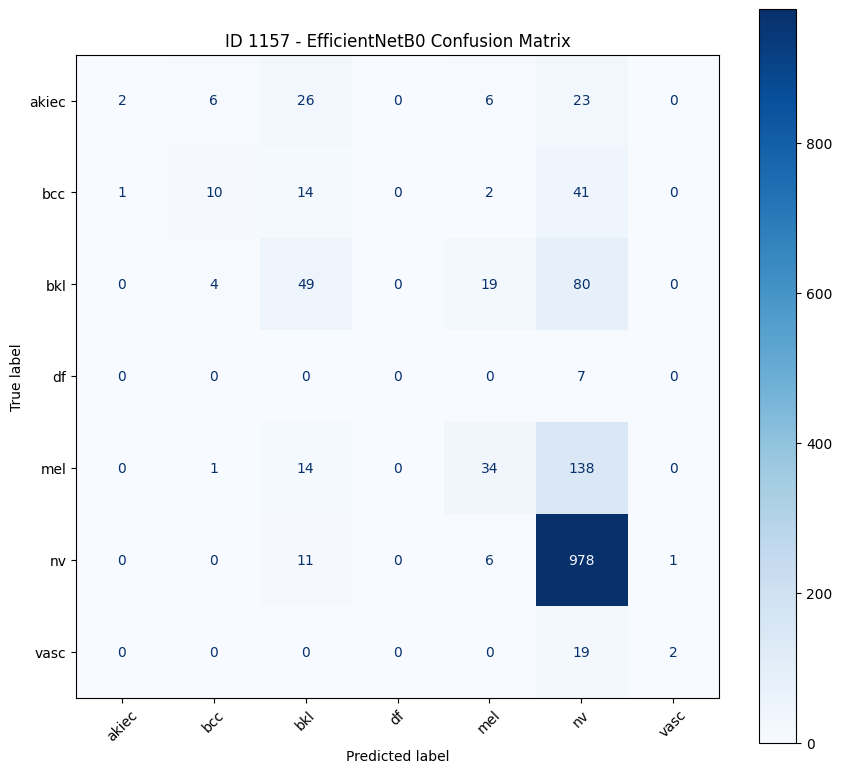


EfficientNetB0 Results Saved Successfully!


In [ ]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    f1_score
)

print("=== ID 1157 EfficientNetB0 Classification Report ===")

# Generate predictions
y_prob_efficient = efficient_best_model.predict(
    efficient_test_ds,
    verbose=1
)

y_pred_efficient = np.argmax(
    y_prob_efficient, axis=1
)

# Get true labels in matching order
y_true_efficient = np.concatenate([
    labels.numpy()
    for images, labels in efficient_test_ds
])

assert len(y_true_efficient) == len(y_pred_efficient), \
    "Prediction count mismatch!"

# Calculate metrics
report = classification_report(
    y_true_efficient,
    y_pred_efficient,
    labels=list(range(len(classes))),
    target_names=classes,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

print("\nClassification Report:")
display(report_df.round(4))

test_accuracy = accuracy_score(
    y_true_efficient, y_pred_efficient
)

macro_f1 = f1_score(
    y_true_efficient,
    y_pred_efficient,
    average="macro"
)

weighted_f1 = f1_score(
    y_true_efficient,
    y_pred_efficient,
    average="weighted"
)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Macro F1-Score: {macro_f1:.4f}")
print(f"Weighted F1-Score: {weighted_f1:.4f}")

# Save results
results_dir = os.path.join(BASE, "results")
os.makedirs(results_dir, exist_ok=True)

report_df.to_csv(
    os.path.join(
        results_dir,
        "efficientnetb0_classification_report.csv"
    )
)

summary_df = pd.DataFrame([{
    "model": "EfficientNetB0",
    "test_accuracy": test_accuracy,
    "macro_f1": macro_f1,
    "weighted_f1": weighted_f1,
    "test_loss": efficient_test_loss
}])

summary_df.to_csv(
    os.path.join(
        results_dir,
        "efficientnetb0_metrics.csv"
    ),
    index=False
)

# Confusion matrix
cm = confusion_matrix(
    y_true_efficient,
    y_pred_efficient,
    labels=list(range(len(classes)))
)

fig, ax = plt.subplots(figsize=(9, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)

disp.plot(ax=ax, cmap="Blues", values_format="d")

plt.title("ID 1157 - EfficientNetB0 Confusion Matrix")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    os.path.join(
        results_dir,
        "efficientnetb0_confusion_matrix.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nEfficientNetB0 Results Saved Successfully!")


In [ ]:

import os
import tensorflow as tf

print("=== ID 1157: Grad-CAM Backbone Fix ===")

# Select the correct ResNet50 backbone
backbone = resnet_best_model.get_layer("resnet50")

# Select the last convolutional feature layer
last_conv_layer = backbone.get_layer("conv5_block3_out")

print("Correct Backbone:", backbone.name)
print("Last Conv Layer:", last_conv_layer.name)
print("Backbone Output:", backbone.output.shape)
print("Conv Layer Output:", last_conv_layer.output.shape)

# Create Grad-CAM results folder
gradcam_dir = os.path.join(
    BASE, "results", "gradcam"
)

os.makedirs(gradcam_dir, exist_ok=True)

print("Grad-CAM Folder:", gradcam_dir)
print("Step 10.1 Fixed Successfully!")


=== ID 1157: Grad-CAM Backbone Fix ===
Correct Backbone: resnet50
Last Conv Layer: conv5_block3_out
Backbone Output: (None, 7, 7, 2048)
Conv Layer Output: (None, 7, 7, 2048)
Grad-CAM Folder: /content/drive1157_new/MyDrive/ID1157_Research/results/gradcam
Step 10.1 Fixed Successfully!


=== ID 1157: ResNet50 Grad-CAM ===


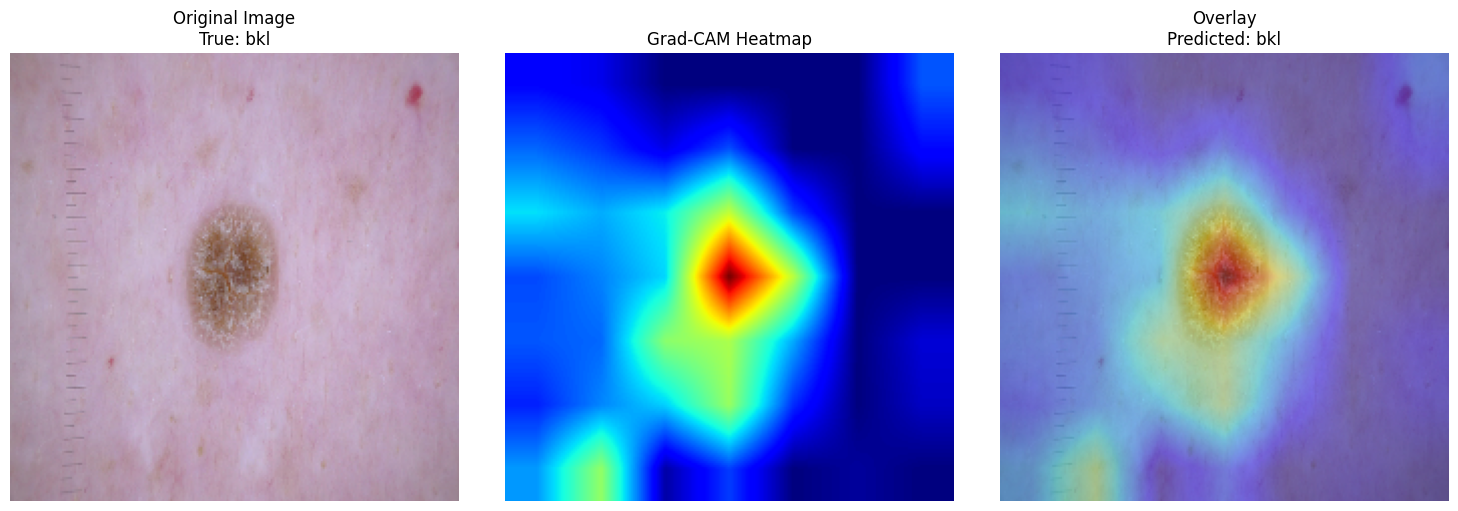

True Class: bkl
Predicted Class: bkl
Grad-CAM Saved: /content/drive1157_new/MyDrive/ID1157_Research/results/gradcam/resnet50_gradcam_sample.png
Step 10.2 Completed!


In [ ]:

import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

print("=== ID 1157: ResNet50 Grad-CAM ===")

# Check required variables
assert "resnet_best_model" in globals()
assert "resnet_test_ds" in globals()
assert "classes" in globals()

# Select one test image
for images, labels in resnet_test_ds.take(1):
    input_image = images[:1]
    true_label = int(labels[0].numpy())

# Get ResNet50 backbone
backbone = resnet_best_model.get_layer("resnet50")

# Create a model that returns feature maps and predictions
feature_extractor = tf.keras.Model(
    inputs=backbone.input,
    outputs=[
        backbone.get_layer("conv5_block3_out").output,
        backbone.output
    ]
)

# Classification head layers
pool_layer = resnet_best_model.get_layer(
    "global_average_pooling2d"
)
dropout_layer = resnet_best_model.get_layer("dropout")
dense_layer = resnet_best_model.get_layer("dense")

# Generate Grad-CAM
with tf.GradientTape() as tape:
    conv_outputs, features = feature_extractor(
        input_image, training=False
    )

    x = pool_layer(features)
    x = dropout_layer(x, training=False)
    predictions = dense_layer(x)

    predicted_class = tf.argmax(
        predictions[0]
    )

    class_score = predictions[
        :, predicted_class
    ]

grads = tape.gradient(
    class_score, conv_outputs
)

assert grads is not None, \
    "Gradients could not be calculated!"

pooled_grads = tf.reduce_mean(
    grads, axis=(0, 1, 2)
)

heatmap = tf.reduce_sum(
    conv_outputs[0] * pooled_grads,
    axis=-1
)

heatmap = tf.maximum(heatmap, 0)

heatmap = heatmap / (
    tf.reduce_max(heatmap) + 1e-8
)

heatmap = heatmap.numpy()

# Convert ResNet50-preprocessed image to RGB
# ResNet50 preprocessing uses BGR and subtracts means
image_np = input_image[0].numpy().copy()

image_np[..., 0] += 103.939
image_np[..., 1] += 116.779
image_np[..., 2] += 123.68

image_np = image_np[..., ::-1]
image_np = np.clip(image_np, 0, 255).astype("uint8")

# Resize heatmap to image dimensions
heatmap_resized = tf.image.resize(
    heatmap[..., np.newaxis],
    (224, 224)
).numpy().squeeze()

# Display results
predicted_idx = int(predicted_class.numpy())

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image_np)
axes[0].set_title(
    f"Original Image\nTrue: {classes[true_label]}"
)

axes[1].imshow(heatmap_resized, cmap="jet")
axes[1].set_title("Grad-CAM Heatmap")

axes[2].imshow(image_np)
axes[2].imshow(
    heatmap_resized,
    cmap="jet",
    alpha=0.4
)
axes[2].set_title(
    f"Overlay\nPredicted: {classes[predicted_idx]}"
)

for ax in axes:
    ax.axis("off")

plt.tight_layout()

# Save figure
gradcam_dir = os.path.join(
    BASE, "results", "gradcam"
)
os.makedirs(gradcam_dir, exist_ok=True)

save_path = os.path.join(
    gradcam_dir,
    "resnet50_gradcam_sample.png"
)

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("True Class:", classes[true_label])
print("Predicted Class:", classes[predicted_idx])
print("Grad-CAM Saved:", save_path)
print("Step 10.2 Completed!")


=== ID 1157: Multi-Class Grad-CAM ===


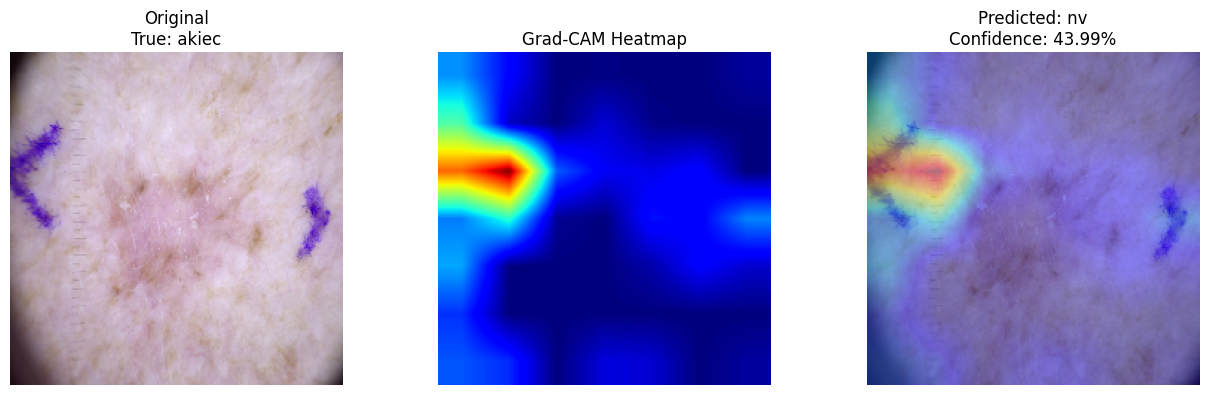

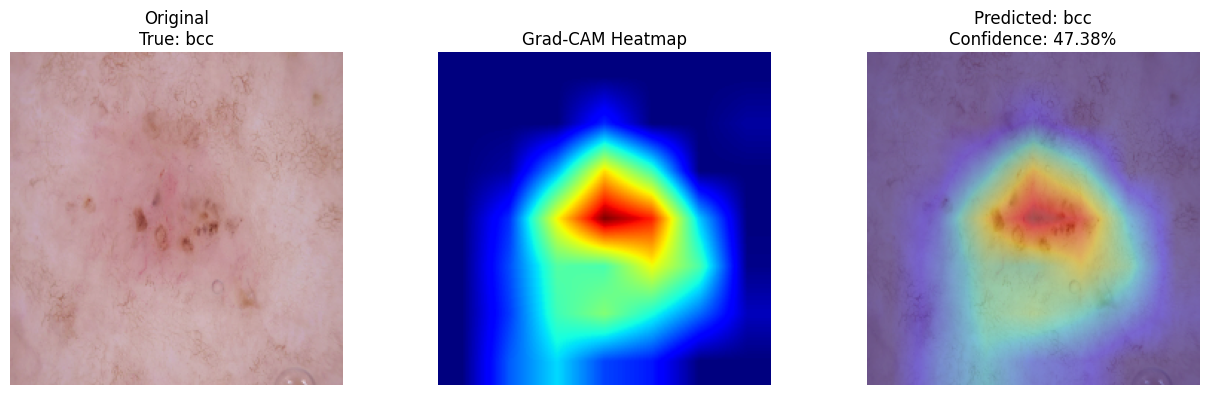

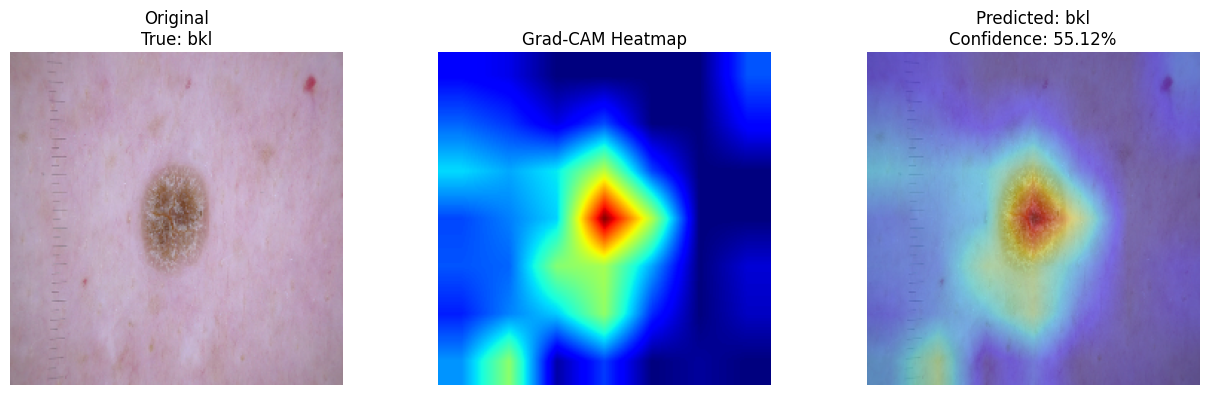

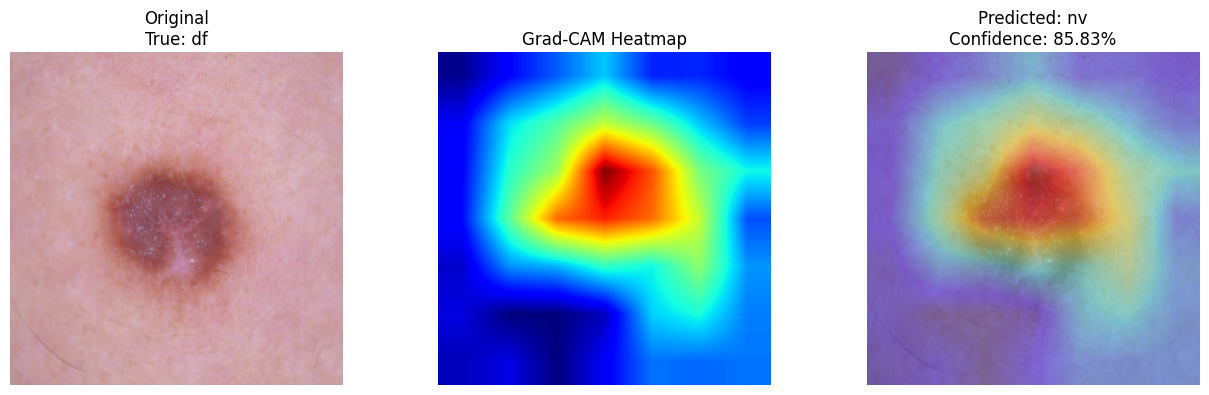

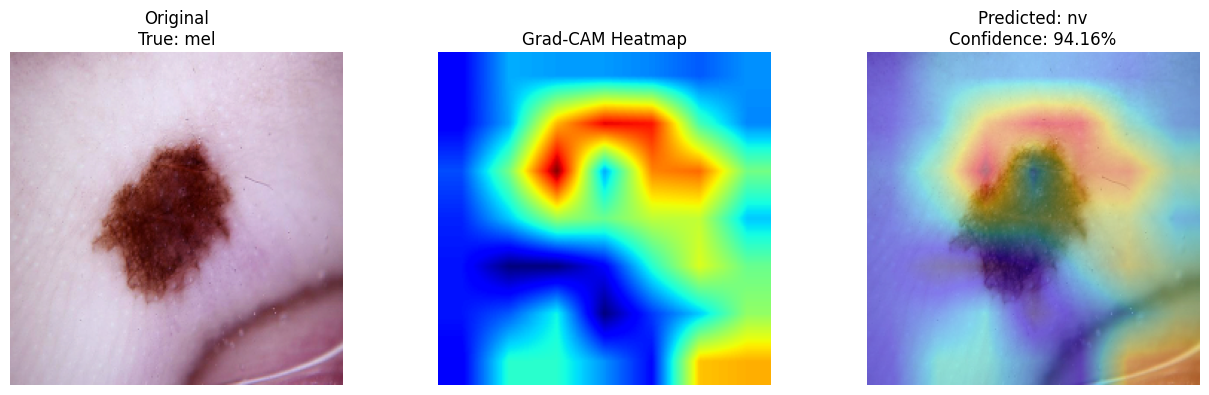

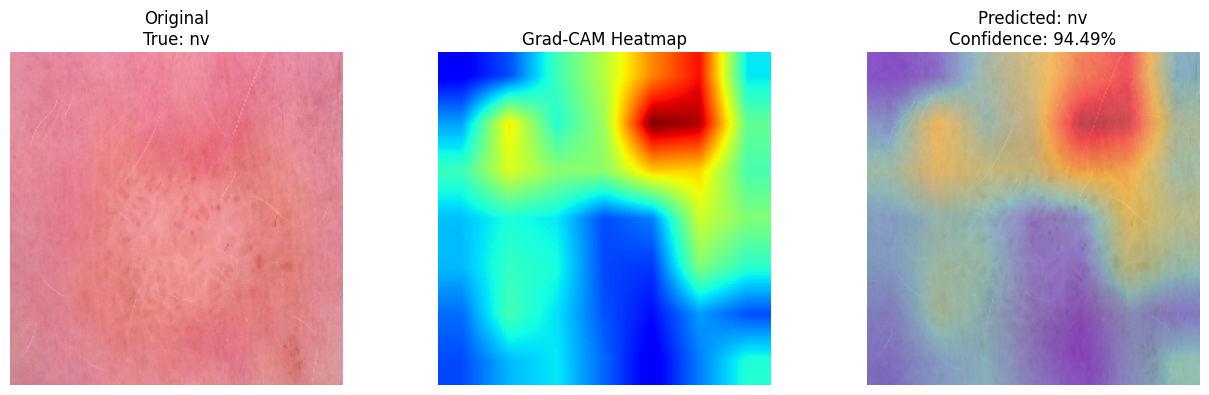

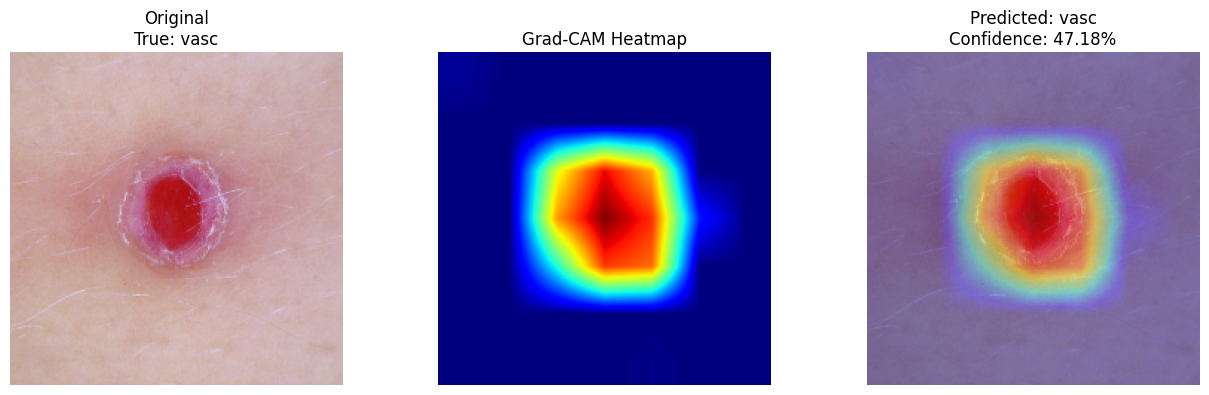


=== Grad-CAM Summary ===


,true_class,predicted_class,confidence,correct
0,akiec,nv,0.439920,False
1,bcc,bcc,0.473799,True
2,bkl,bkl,0.551218,True
3,df,nv,0.858261,False
4,mel,nv,0.941571,False
5,nv,nv,0.944864,True
6,vasc,vasc,0.471771,True



Total Grad-CAM figures: 7
Saved folder: /content/drive1157_new/MyDrive/ID1157_Research/results/gradcam
Step 10.3 Completed Successfully!


In [ ]:

import os
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

print("=== ID 1157: Multi-Class Grad-CAM ===")

# Safety checks
assert "resnet_best_model" in globals(), "Load ResNet50 first!"
assert "resnet_test_ds" in globals(), "Restore test dataset first!"
assert "classes" in globals(), "Class labels missing!"

BASE = "/content/drive1157_new/MyDrive/ID1157_Research"

gradcam_dir = os.path.join(
    BASE, "results", "gradcam"
)
os.makedirs(gradcam_dir, exist_ok=True)

# Get saved model components
backbone = resnet_best_model.get_layer("resnet50")
augmentation = resnet_best_model.get_layer(
    "resnet_augmentation"
)
pool_layer = resnet_best_model.get_layer(
    "global_average_pooling2d"
)
dropout_layer = resnet_best_model.get_layer("dropout")
dense_layer = resnet_best_model.get_layer("dense")

# Feature extractor for Grad-CAM
feature_extractor = tf.keras.Model(
    inputs=backbone.input,
    outputs=[
        backbone.get_layer("conv5_block3_out").output,
        backbone.output
    ]
)

def generate_gradcam(image_batch):
    image_batch = tf.convert_to_tensor(
        image_batch, dtype=tf.float32
    )

    # Full saved-model prediction
    full_predictions = resnet_best_model(
        image_batch, training=False
    )

    predicted_idx = int(
        tf.argmax(full_predictions[0]).numpy()
    )

    confidence = float(
        full_predictions[0, predicted_idx].numpy()
    )

    with tf.GradientTape() as tape:
        # Apply augmentation in inference mode
        x = augmentation(image_batch, training=False)

        # Extract convolutional feature maps
        conv_outputs, features = feature_extractor(
            x, training=False
        )

        # Reconstruct classification head
        x = pool_layer(features)
        x = dropout_layer(x, training=False)
        predictions = dense_layer(x)

        class_score = predictions[:, predicted_idx]

    # Verify reconstructed predictions
    np.testing.assert_allclose(
        full_predictions.numpy(),
        predictions.numpy(),
        rtol=1e-4,
        atol=1e-5
    )

    grads = tape.gradient(
        class_score, conv_outputs
    )

    if grads is None:
        raise ValueError("Grad-CAM gradients unavailable!")

    pooled_grads = tf.reduce_mean(
        grads, axis=(0, 1, 2)
    )

    heatmap = tf.reduce_sum(
        conv_outputs[0] * pooled_grads,
        axis=-1
    )

    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (
        tf.reduce_max(heatmap) + 1e-8
    )

    return heatmap.numpy(), predicted_idx, confidence

def restore_rgb(preprocessed_image):
    # Reverse ResNet50 preprocessing:
    # BGR mean subtraction -> RGB image
    image = preprocessed_image.copy()

    image[..., 0] += 103.939
    image[..., 1] += 116.779
    image[..., 2] += 123.68

    image = image[..., ::-1]

    return np.clip(image, 0, 255).astype("uint8")

# Select one sample from each true class
selected = {}

for images, labels in resnet_test_ds:
    images_np = images.numpy()
    labels_np = labels.numpy()

    for i, label in enumerate(labels_np):
        label = int(label)

        if label not in selected:
            selected[label] = images_np[i:i+1]

    if len(selected) == len(classes):
        break

assert len(selected) == len(classes), \
    "Could not find a sample for every class!"

results = []

for class_idx in range(len(classes)):
    image_batch = selected[class_idx]

    heatmap, predicted_idx, confidence = (
        generate_gradcam(image_batch)
    )

    # Resize heatmap
    heatmap_resized = tf.image.resize(
        heatmap[..., np.newaxis],
        (224, 224)
    ).numpy().squeeze()

    rgb_image = restore_rgb(image_batch[0])

    true_class = classes[class_idx]
    predicted_class = classes[predicted_idx]

    # Create figure
    fig, axes = plt.subplots(
        1, 3, figsize=(13, 4)
    )

    axes[0].imshow(rgb_image)
    axes[0].set_title(
        f"Original\nTrue: {true_class}"
    )

    axes[1].imshow(
        heatmap_resized,
        cmap="jet",
        vmin=0,
        vmax=1
    )
    axes[1].set_title("Grad-CAM Heatmap")

    axes[2].imshow(rgb_image)
    axes[2].imshow(
        heatmap_resized,
        cmap="jet",
        alpha=0.4,
        vmin=0,
        vmax=1
    )
    axes[2].set_title(
        f"Predicted: {predicted_class}\n"
        f"Confidence: {confidence:.2%}"
    )

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()

    save_path = os.path.join(
        gradcam_dir,
        f"resnet50_gradcam_{true_class}.png"
    )

    plt.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    results.append({
        "true_class": true_class,
        "predicted_class": predicted_class,
        "confidence": confidence,
        "correct": true_class == predicted_class,
        "figure_path": save_path
    })

# Save summary
results_df = pd.DataFrame(results)

results_df.to_csv(
    os.path.join(
        gradcam_dir,
        "resnet50_gradcam_summary.csv"
    ),
    index=False
)

print("\n=== Grad-CAM Summary ===")
display(results_df[
    ["true_class", "predicted_class",
     "confidence", "correct"]
])

print("\nTotal Grad-CAM figures:", len(results_df))
print("Saved folder:", gradcam_dir)
print("Step 10.3 Completed Successfully!")


In [ ]:

import os
import pandas as pd
import numpy as np

print("=== ID 1157: Final Model Comparison ===")

BASE = "/content/drive1157_new/MyDrive/ID1157_Research"
RESULTS = os.path.join(BASE, "results")

models = {
    "MobileNetV2": {
        "report": "mobilenetv2_classification_report.csv",
        "loss": 0.7470
    },
    "ResNet50": {
        "report": "resnet50_classification_report.csv",
        "loss": 0.6443
    },
    "EfficientNetB0": {
        "report": "efficientnetb0_classification_report.csv",
        "loss": 0.7360
    }
}

comparison = []

for model_name, info in models.items():

    report_path = os.path.join(
        RESULTS, info["report"]
    )

    assert os.path.isfile(report_path), (
        f"Report not found: {report_path}"
    )

    report = pd.read_csv(
        report_path,
        index_col=0
    )

    # Verify required report rows
    for row in ["accuracy", "macro avg",
                "weighted avg", "mel"]:
        assert row in report.index, (
            f"{row} missing in {model_name}"
        )

    accuracy = float(
        report.loc["accuracy", "precision"]
    )

    macro_precision = float(
        report.loc["macro avg", "precision"]
    )

    macro_recall = float(
        report.loc["macro avg", "recall"]
    )

    macro_f1 = float(
        report.loc["macro avg", "f1-score"]
    )

    weighted_f1 = float(
        report.loc["weighted avg", "f1-score"]
    )

    melanoma_recall = float(
        report.loc["mel", "recall"]
    )

    comparison.append({
        "Model": model_name,
        "Test Accuracy": accuracy,
        "Macro Precision": macro_precision,
        "Macro Recall": macro_recall,
        "Macro F1": macro_f1,
        "Weighted F1": weighted_f1,
        "Melanoma Recall": melanoma_recall,
        "Test Loss": info["loss"]
    })

comparison_df = pd.DataFrame(comparison)

# Sort by Macro F1, important for imbalanced data
comparison_df = comparison_df.sort_values(
    "Macro F1",
    ascending=False
).reset_index(drop=True)

print("\n=== Final Comparison Table ===")
display(comparison_df.round(4))

# Save original numeric results
comparison_path = os.path.join(
    RESULTS,
    "final_model_comparison.csv"
)

comparison_df.to_csv(
    comparison_path,
    index=False
)

print("\nComparison Saved Successfully!")
print("Saved file:", comparison_path)

print("\nHighest Macro F1 Model:",
      comparison_df.iloc[0]["Model"])

print("Step 11.1 Completed!")


=== ID 1157: Final Model Comparison ===

=== Final Comparison Table ===


,Model,Test Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Melanoma Recall,Test Loss
0,ResNet50,0.7751,0.6211,0.3989,0.4418,0.7541,0.4599,0.6443
1,MobileNetV2,0.7410,0.5250,0.3985,0.4230,0.7109,0.2620,0.7470
2,EfficientNetB0,0.7195,0.5010,0.2515,0.2779,0.6575,0.1818,0.7360



Comparison Saved Successfully!
Saved file: /content/drive1157_new/MyDrive/ID1157_Research/results/final_model_comparison.csv

Highest Macro F1 Model: ResNet50
Step 11.1 Completed!


=== ID 1157: Model Comparison Graphs ===


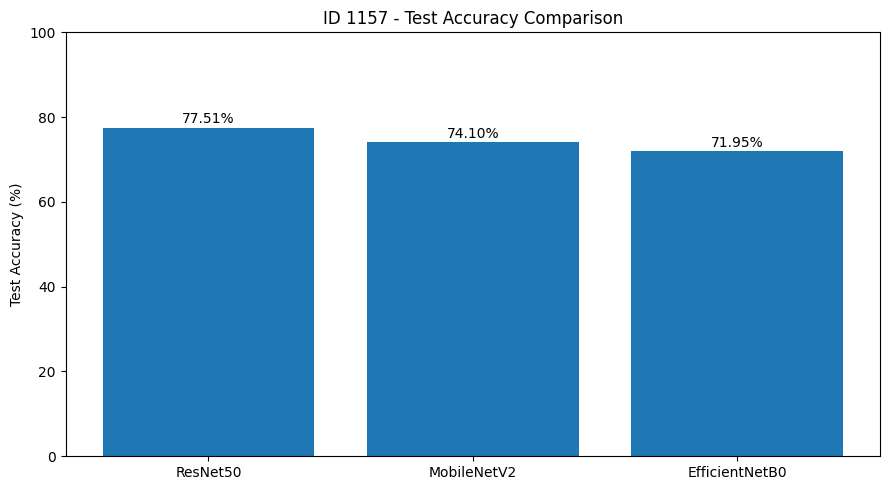

Saved: /content/drive1157_new/MyDrive/ID1157_Research/results/model_accuracy_comparison.png


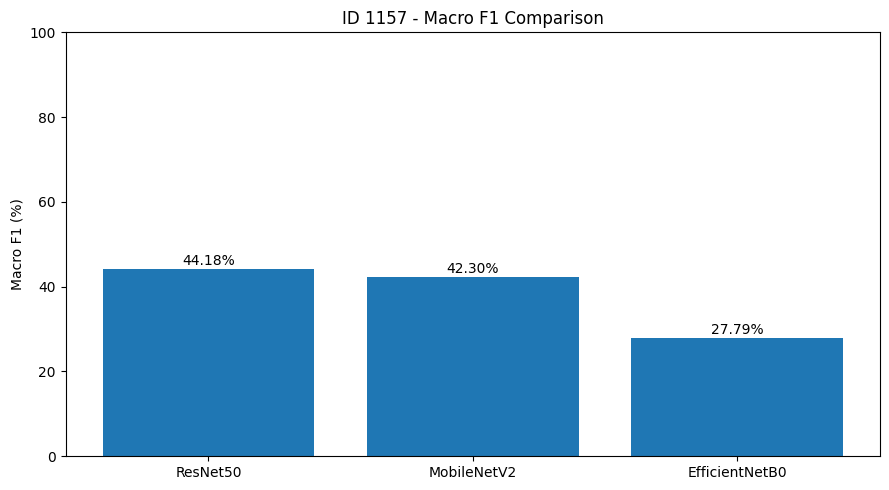

Saved: /content/drive1157_new/MyDrive/ID1157_Research/results/model_macro_f1_comparison.png


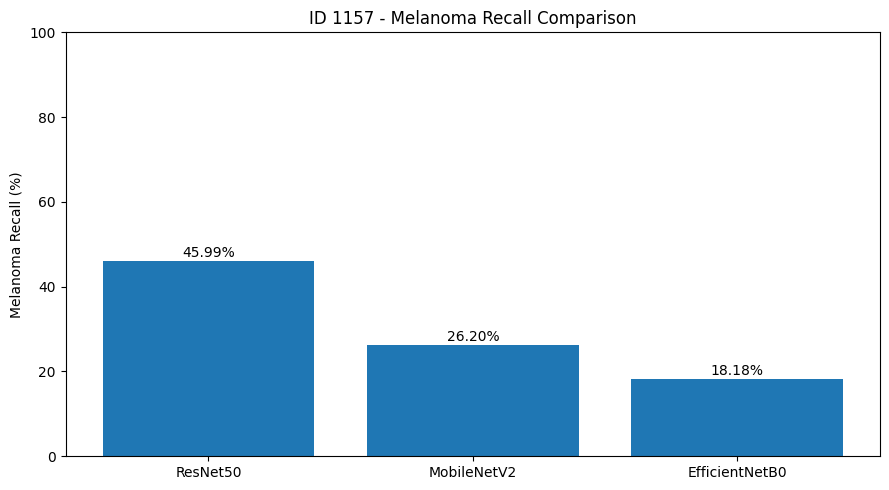

Saved: /content/drive1157_new/MyDrive/ID1157_Research/results/model_melanoma_recall_comparison.png

Step 11.2 Completed Successfully!


In [ ]:

import os
import pandas as pd
import matplotlib.pyplot as plt

print("=== ID 1157: Model Comparison Graphs ===")

BASE = "/content/drive1157_new/MyDrive/ID1157_Research"
RESULTS = os.path.join(BASE, "results")

# Load saved comparison
comparison_df = pd.read_csv(
    os.path.join(RESULTS, "final_model_comparison.csv")
)

metrics = {
    "Test Accuracy": "model_accuracy_comparison.png",
    "Macro F1": "model_macro_f1_comparison.png",
    "Melanoma Recall": "model_melanoma_recall_comparison.png"
}

for metric, filename in metrics.items():

    fig, ax = plt.subplots(figsize=(9, 5))

    values = comparison_df[metric] * 100

    bars = ax.bar(
        comparison_df["Model"],
        values
    )

    ax.set_title(
        f"ID 1157 - {metric} Comparison"
    )
    ax.set_ylabel(f"{metric} (%)")
    ax.set_ylim(0, 100)

    # Show exact percentages
    for bar, value in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 1,
            f"{value:.2f}%",
            ha="center"
        )

    plt.tight_layout()

    save_path = os.path.join(RESULTS, filename)

    plt.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print("Saved:", save_path)

print("\nStep 11.2 Completed Successfully!")


In [ ]:

import os
import pandas as pd

print("=== ID 1157: Research Results Summary ===")

BASE = "/content/drive1157_new/MyDrive/ID1157_Research"
RESULTS = os.path.join(BASE, "results")

# Load actual saved evaluation results
comparison_path = os.path.join(
    RESULTS, "final_model_comparison.csv"
)

assert os.path.isfile(comparison_path), \
    "Comparison CSV not found!"

df = pd.read_csv(comparison_path)

required = [
    "Model", "Test Accuracy", "Macro Precision",
    "Macro Recall", "Macro F1", "Weighted F1",
    "Melanoma Recall", "Test Loss"
]

assert all(c in df.columns for c in required), \
    "Some required metrics are missing!"

# Format table for research paper
paper_df = df.copy()

percent_cols = [
    "Test Accuracy", "Macro Precision",
    "Macro Recall", "Macro F1",
    "Weighted F1", "Melanoma Recall"
]

for col in percent_cols:
    paper_df[col] = paper_df[col].map(
        lambda x: f"{x * 100:.2f}%"
    )

paper_df["Test Loss"] = paper_df[
    "Test Loss"
].map(lambda x: f"{x:.4f}")

print("\n=== Research Paper Comparison Table ===")
display(paper_df)

# Save formatted table
paper_table_path = os.path.join(
    RESULTS, "research_paper_comparison_table.csv"
)

paper_df.to_csv(
    paper_table_path, index=False
)

# Identify best model by macro F1
best = df.loc[df["Macro F1"].idxmax()]

# Generate factual summary
summary = f"""
ID 1157 - Research Results Summary

Research Topic:
An Explainable Deep Learning Framework for
Multi-Class Skin Lesion Classification Using Transfer Learning

Dataset: HAM10000
Number of classes: 7
Test images: 1494

Models evaluated:
MobileNetV2, ResNet50, EfficientNetB0

Best model by Macro F1:
{best['Model']}

Best model test accuracy:
{best['Test Accuracy'] * 100:.2f}%

Best model macro F1-score:
{best['Macro F1'] * 100:.2f}%

Best model melanoma recall:
{best['Melanoma Recall'] * 100:.2f}%

Explainability:
Grad-CAM visualizations were generated for ResNet50
using selected test images from all seven classes.

Important limitations:
- Performance varies substantially across lesion classes.
- Minority-class recognition remains weak.
- Grad-CAM visualizations do not establish clinical validity.
- ResNet50 augmentation/preprocessing order requires
  correction or explicit methodological qualification.
- External clinical validation has not been performed.
"""

summary_path = os.path.join(
    RESULTS, "research_results_summary.txt"
)

with open(summary_path, "w", encoding="utf-8") as f:
    f.write(summary)

print(summary)

print("\nSaved files:")
print(paper_table_path)
print(summary_path)

print("\nStep 11.3 Completed Successfully!")


=== ID 1157: Research Results Summary ===

=== Research Paper Comparison Table ===


,Model,Test Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Melanoma Recall,Test Loss
0,ResNet50,77.51%,62.11%,39.89%,44.18%,75.41%,45.99%,0.6443
1,MobileNetV2,74.10%,52.50%,39.85%,42.30%,71.09%,26.20%,0.7470
2,EfficientNetB0,71.95%,50.10%,25.15%,27.79%,65.75%,18.18%,0.7360



ID 1157 - Research Results Summary

Research Topic:
An Explainable Deep Learning Framework for
Multi-Class Skin Lesion Classification Using Transfer Learning

Dataset: HAM10000
Number of classes: 7
Test images: 1494

Models evaluated:
MobileNetV2, ResNet50, EfficientNetB0

Best model by Macro F1:
ResNet50

Best model test accuracy:
77.51%

Best model macro F1-score:
44.18%

Best model melanoma recall:
45.99%

Explainability:
Grad-CAM visualizations were generated for ResNet50
using selected test images from all seven classes.

Important limitations:
- Performance varies substantially across lesion classes.
- Minority-class recognition remains weak.
- Grad-CAM visualizations do not establish clinical validity.
- ResNet50 augmentation/preprocessing order requires
  correction or explicit methodological qualification.
- External clinical validation has not been performed.


Saved files:
/content/drive1157_new/MyDrive/ID1157_Research/results/research_paper_comparison_table.csv
/content/dr

In [ ]:

from google.colab import drive
import os

# Mount Google Drive at a fresh location
MOUNT = "/content/drive1157_reconnect"
drive.mount(MOUNT)

# Search for the saved split files
root = os.path.join(MOUNT, "MyDrive")

found = []

for folder, dirs, files in os.walk(root):
    if "train.csv" in files and "test.csv" in files:
        found.append(folder)
        print("FOUND SPLITS:", folder)

        print("Files:", sorted(files))

if found:
    SPLITS = found[0]
    BASE = os.path.dirname(SPLITS)
    RESULTS = os.path.join(BASE, "results")

    print("\nBASE =", BASE)
    print("SPLITS =", SPLITS)
    print("RESULTS =", RESULTS)
else:
    print("Split files not found. Check Google Drive account.")


Mounted at /content/drive1157_reconnect
FOUND SPLITS: /content/drive1157_reconnect/MyDrive/ID1157_Research/splits
Files: ['test.csv', 'train.csv', 'validation.csv']

BASE = /content/drive1157_reconnect/MyDrive/ID1157_Research
SPLITS = /content/drive1157_reconnect/MyDrive/ID1157_Research/splits
RESULTS = /content/drive1157_reconnect/MyDrive/ID1157_Research/results


=== ID 1157: Class Distribution Figure ===

=== Actual Class Distribution ===


,Train,Validation,Test,Total
dx,,,,
akiec,207,57,63,327
bcc,381,65,68,514
bkl,741,206,152,1099
df,89,19,7,115
mel,770,156,187,1113
nv,4718,991,996,6705
vasc,96,25,21,142


Total Images: 10015
Saved: /content/drive1157_reconnect/MyDrive/ID1157_Research/results/ham10000_class_distribution.png
Saved: /content/drive1157_reconnect/MyDrive/ID1157_Research/results/ham10000_class_distribution.jpg


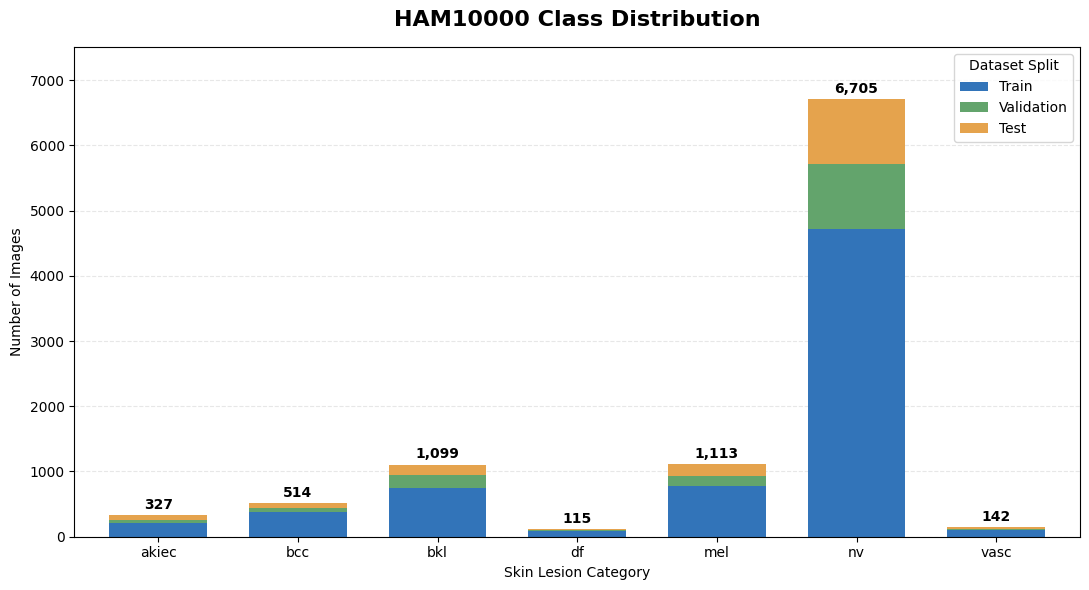


Class Distribution Figure Completed!


In [ ]:

import os
import pandas as pd
import matplotlib.pyplot as plt

print("=== ID 1157: Class Distribution Figure ===")

BASE = "/content/drive1157_reconnect/MyDrive/ID1157_Research"
SPLITS = os.path.join(BASE, "splits")
RESULTS = os.path.join(BASE, "results")

os.makedirs(RESULTS, exist_ok=True)

# Load actual dataset splits
train = pd.read_csv(os.path.join(SPLITS, "train.csv"))
val = pd.read_csv(os.path.join(SPLITS, "validation.csv"))
test = pd.read_csv(os.path.join(SPLITS, "test.csv"))

classes = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]

distribution = pd.DataFrame({
    "Train": train["dx"].value_counts().reindex(classes, fill_value=0),
    "Validation": val["dx"].value_counts().reindex(classes, fill_value=0),
    "Test": test["dx"].value_counts().reindex(classes, fill_value=0)
})

distribution["Total"] = distribution.sum(axis=1)

print("\n=== Actual Class Distribution ===")
display(distribution)

total_images = int(distribution["Total"].sum())
print("Total Images:", total_images)

# Validate counts before plotting
assert total_images == 10015, (
    f"Expected 10015 images, found {total_images}. "
    "Check dataset splits before using the figure."
)

# Create publication-ready figure
plt.style.use("default")

fig, ax = plt.subplots(
    figsize=(11, 6),
    facecolor="white"
)

distribution[["Train", "Validation", "Test"]].plot(
    kind="bar",
    stacked=True,
    ax=ax,
    color=["#3274B9", "#63A46C", "#E5A34D"],
    width=0.7
)

ax.set_title(
    "HAM10000 Class Distribution",
    fontsize=16,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Skin Lesion Category")
ax.set_ylabel("Number of Images")
ax.set_xticklabels(classes, rotation=0)

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

for i, count in enumerate(distribution["Total"]):
    ax.text(
        i,
        count + distribution["Total"].max() * 0.015,
        f"{count:,}",
        ha="center",
        fontsize=10,
        fontweight="bold"
    )

ax.set_ylim(
    0,
    distribution["Total"].max() * 1.12
)

ax.legend(title="Dataset Split")
plt.tight_layout()

# Save PNG and JPG
for ext in ["png", "jpg"]:
    path = os.path.join(
        RESULTS,
        f"ham10000_class_distribution.{ext}"
    )
    fig.savefig(
        path,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )
    print("Saved:", path)

plt.show()
plt.close(fig)

print("\nClass Distribution Figure Completed!")


=== ID 1157: Training Accuracy Curves ===
Saved: /content/drive1157_reconnect/MyDrive/ID1157_Research/results/training_validation_accuracy.png
Saved: /content/drive1157_reconnect/MyDrive/ID1157_Research/results/training_validation_accuracy.jpg


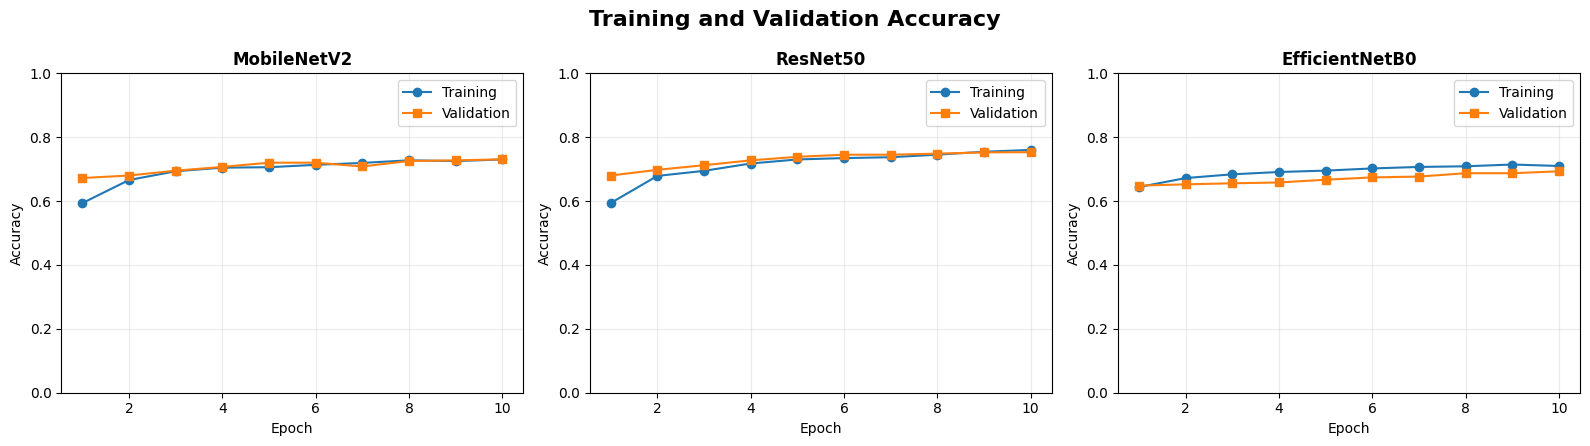


Accuracy Curves Completed!


In [ ]:

import os
import pandas as pd
import matplotlib.pyplot as plt

print("=== ID 1157: Training Accuracy Curves ===")

BASE = "/content/drive1157_reconnect/MyDrive/ID1157_Research"
MODELS = os.path.join(BASE, "models")
RESULTS = os.path.join(BASE, "results")

logs = {
    "MobileNetV2": "mobilenetv2_training_log.csv",
    "ResNet50": "resnet50_training_log.csv",
    "EfficientNetB0": "efficientnetb0_training_log.csv"
}

fig, axes = plt.subplots(
    1, 3, figsize=(16, 4.5), facecolor="white"
)

for ax, (model, filename) in zip(axes, logs.items()):
    path = os.path.join(MODELS, filename)
    assert os.path.isfile(path), f"Missing: {path}"

    df = pd.read_csv(path)

    assert {"accuracy", "val_accuracy"}.issubset(df.columns), \
        f"Accuracy columns missing in {filename}"

    epochs = range(1, len(df) + 1)

    ax.plot(
        epochs, df["accuracy"],
        marker="o", label="Training"
    )
    ax.plot(
        epochs, df["val_accuracy"],
        marker="s", label="Validation"
    )

    ax.set_title(model, fontweight="bold")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Accuracy")
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.25)
    ax.legend()

fig.suptitle(
    "Training and Validation Accuracy",
    fontsize=16, fontweight="bold"
)

plt.tight_layout()

for ext in ["png", "jpg"]:
    path = os.path.join(
        RESULTS,
        f"training_validation_accuracy.{ext}"
    )
    fig.savefig(
        path, dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )
    print("Saved:", path)

plt.show()
plt.close(fig)

print("\nAccuracy Curves Completed!")


In [ ]:

from google.colab import drive
import os

MOUNT = "/content/drive1157_reconnect"

if not os.path.ismount(MOUNT):
    drive.mount(MOUNT)

BASE = os.path.join(MOUNT, "MyDrive", "ID1157_Research")
MODELS = os.path.join(BASE, "models")
RESULTS = os.path.join(BASE, "results")

os.makedirs(RESULTS, exist_ok=True)

print("Project folder found:", os.path.isdir(BASE))
print("Training logs:", [
    f for f in os.listdir(MODELS)
    if "training_log" in f
])


Mounted at /content/drive1157_reconnect
Project folder found: True
Training logs: ['mobilenetv2_training_log.csv', 'resnet50_training_log.csv', 'efficientnetb0_training_log.csv']


=== ID 1157: Training vs Validation Loss ===
Saved: /content/drive1157_reconnect/MyDrive/ID1157_Research/results/training_validation_loss.png
Saved: /content/drive1157_reconnect/MyDrive/ID1157_Research/results/training_validation_loss.jpg


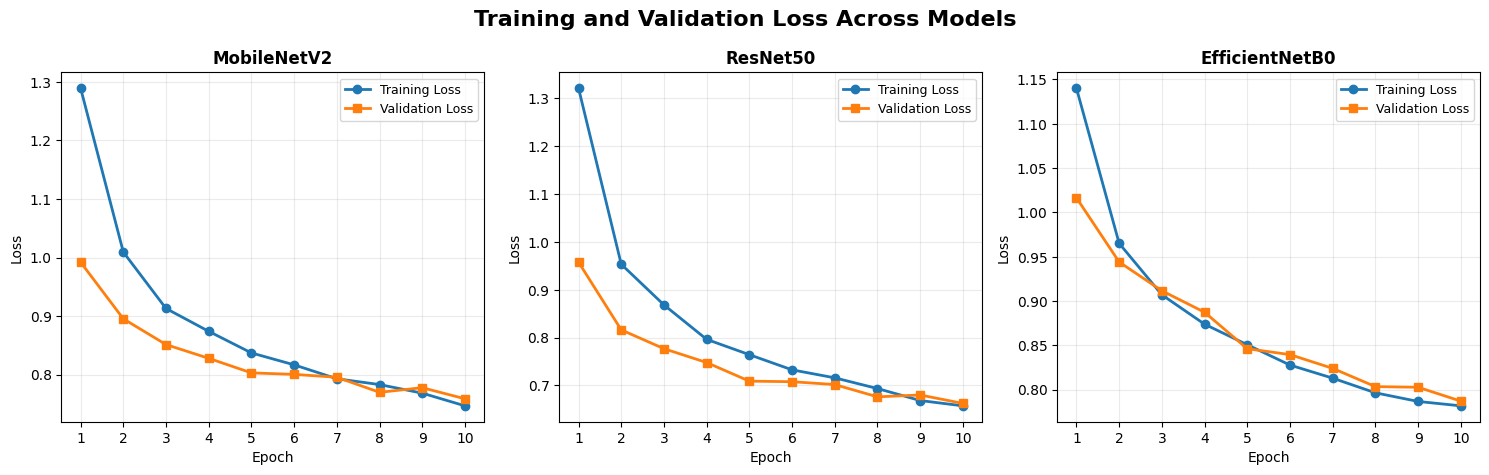


Loss Figure Completed Successfully!


In [ ]:

import os
import pandas as pd
import matplotlib.pyplot as plt

print("=== ID 1157: Training vs Validation Loss ===")

logs = {
    "MobileNetV2": "mobilenetv2_training_log.csv",
    "ResNet50": "resnet50_training_log.csv",
    "EfficientNetB0": "efficientnetb0_training_log.csv"
}

plt.style.use("default")

fig, axes = plt.subplots(
    1, 3, figsize=(15, 4.8), facecolor="white"
)

for ax, (model_name, filename) in zip(axes, logs.items()):
    path = os.path.join(MODELS, filename)

    assert os.path.isfile(path), f"Missing file: {path}"

    df = pd.read_csv(path)

    assert {"loss", "val_loss"}.issubset(df.columns), (
        f"Loss columns missing in {filename}"
    )

    epochs = range(1, len(df) + 1)

    ax.plot(
        epochs, df["loss"],
        marker="o",
        linewidth=2,
        label="Training Loss"
    )

    ax.plot(
        epochs, df["val_loss"],
        marker="s",
        linewidth=2,
        label="Validation Loss"
    )

    ax.set_title(model_name, fontsize=12, fontweight="bold")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.set_xticks(list(epochs))
    ax.grid(alpha=0.25)
    ax.legend(fontsize=9)

fig.suptitle(
    "Training and Validation Loss Across Models",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

for ext in ["png", "jpg"]:
    save_path = os.path.join(
        RESULTS,
        f"training_validation_loss.{ext}"
    )

    fig.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

    print("Saved:", save_path)

plt.show()
plt.close(fig)

print("\nLoss Figure Completed Successfully!")


Saved: /content/drive1157_reconnect/MyDrive/ID1157_Research/results/seven_class_gradcam_final_clear.png
Saved: /content/drive1157_reconnect/MyDrive/ID1157_Research/results/seven_class_gradcam_final_clear.jpg


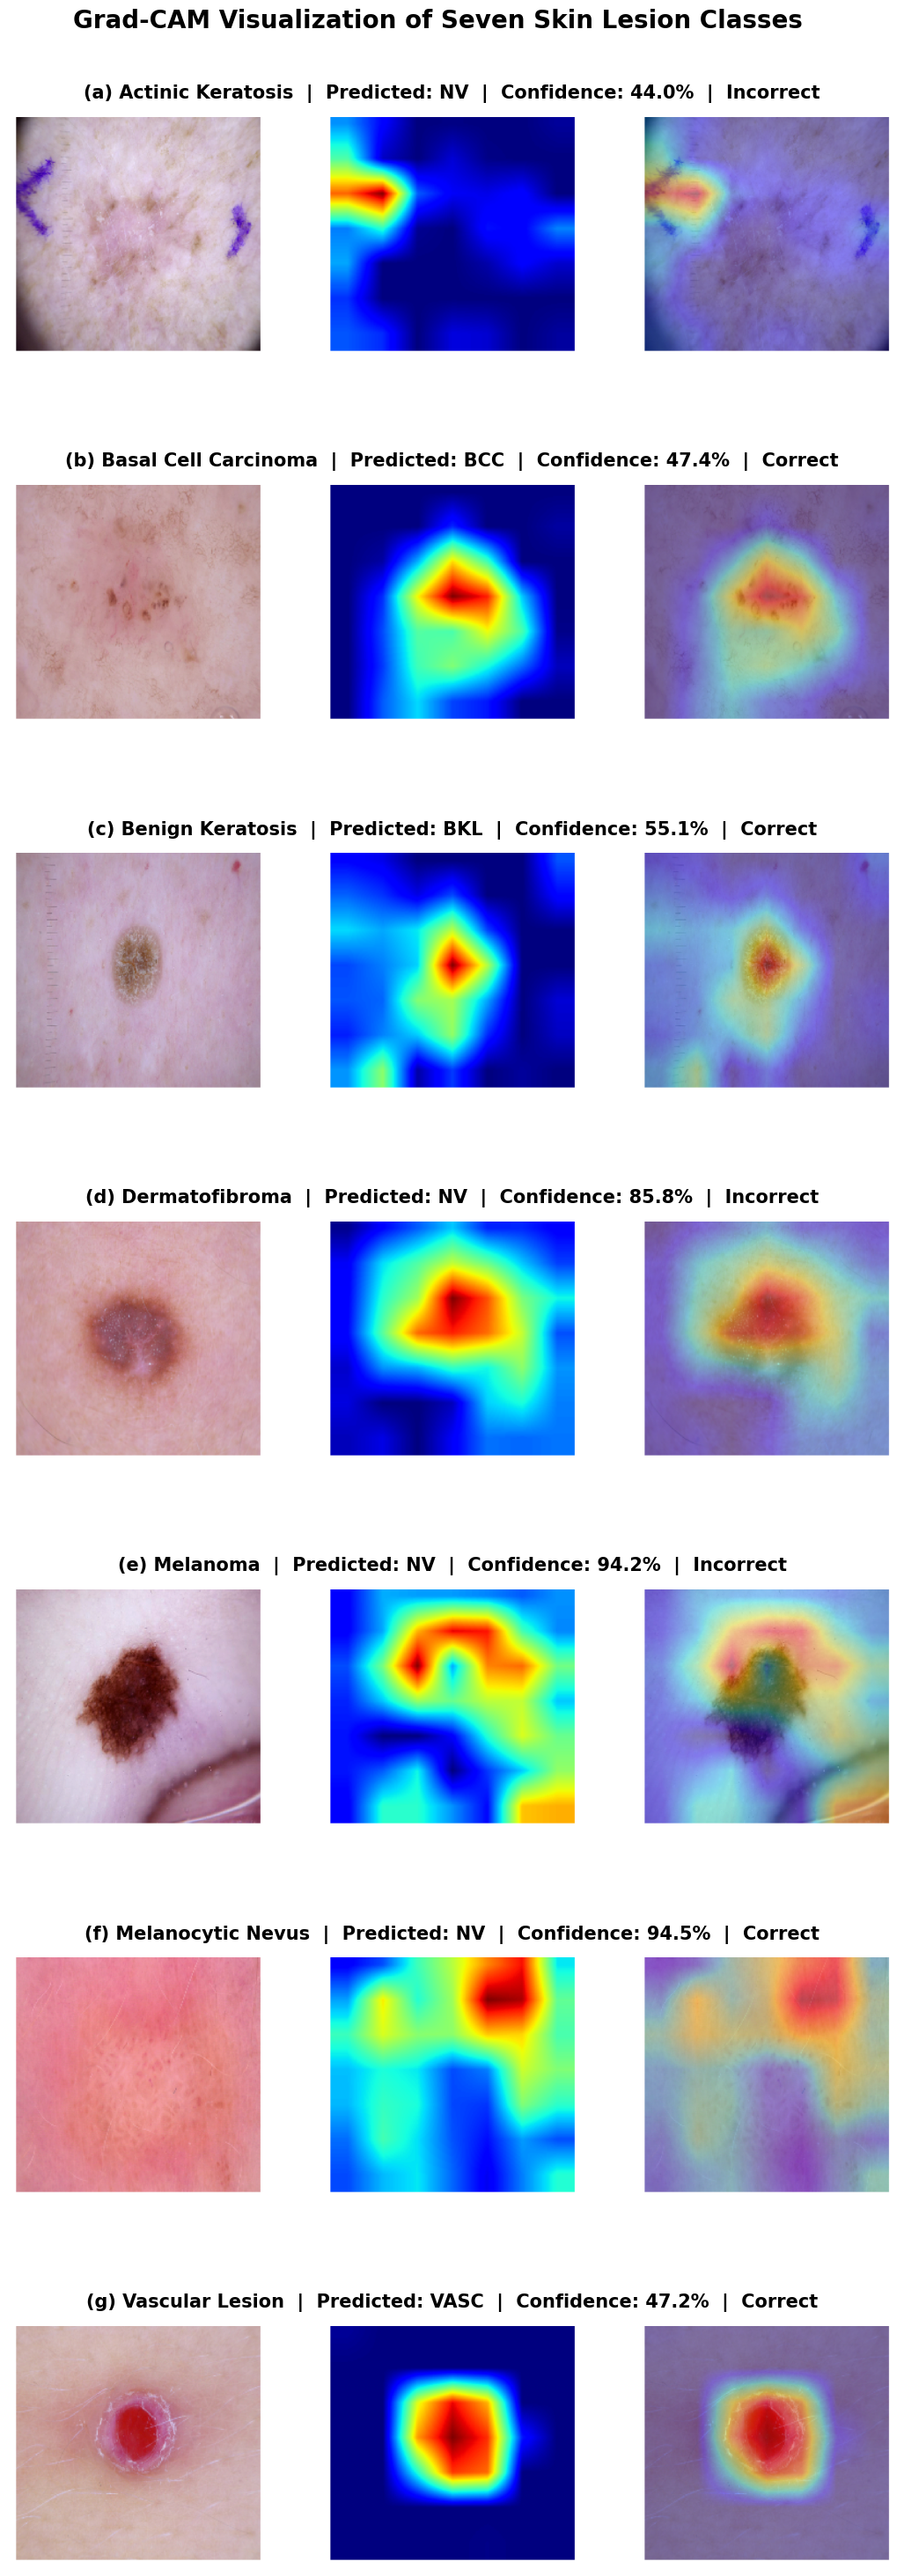


Final Clear Grad-CAM Panel Completed!


In [ ]:

import os
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

BASE = "/content/drive1157_reconnect/MyDrive/ID1157_Research"
GRADCAM = os.path.join(BASE, "results", "gradcam")
RESULTS = os.path.join(BASE, "results")

classes = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]

names = {
    "akiec": "Actinic Keratosis",
    "bcc": "Basal Cell Carcinoma",
    "bkl": "Benign Keratosis",
    "df": "Dermatofibroma",
    "mel": "Melanoma",
    "nv": "Melanocytic Nevus",
    "vasc": "Vascular Lesion"
}

summary = pd.read_csv(
    os.path.join(GRADCAM, "resnet50_gradcam_summary.csv")
)

plt.style.use("default")

# One row per lesion class
fig, axes = plt.subplots(
    7, 1,
    figsize=(13, 30),
    facecolor="white"
)

for i, cls in enumerate(classes):

    path = os.path.join(
        GRADCAM,
        f"resnet50_gradcam_{cls}.png"
    )

    img = Image.open(path).convert("RGB")

    # Crop top 16% containing old title
    w, h = img.size
    cropped = img.crop((0, int(h * 0.16), w, h))

    row = summary[
        summary["true_class"] == cls
    ].iloc[0]

    pred = row["predicted_class"]
    conf = float(row["confidence"])
    status = "Correct" if pred == cls else "Incorrect"

    axes[i].imshow(cropped)
    axes[i].set_title(
        f"({chr(97+i)}) {names[cls]}  |  "
        f"Predicted: {pred.upper()}  |  "
        f"Confidence: {conf:.1%}  |  {status}",
        fontsize=15,
        fontweight="bold",
        pad=15
    )
    axes[i].axis("off")

fig.suptitle(
    "Grad-CAM Visualization of Seven Skin Lesion Classes",
    fontsize=20,
    fontweight="bold",
    y=0.995
)

plt.subplots_adjust(
    top=0.96,
    bottom=0.02,
    hspace=0.35
)

for ext in ["png", "jpg"]:
    save_path = os.path.join(
        RESULTS,
        f"seven_class_gradcam_final_clear.{ext}"
    )
    fig.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )
    print("Saved:", save_path)

plt.show()
plt.close(fig)

print("\nFinal Clear Grad-CAM Panel Completed!")


In [ ]:

# ID 1157 — Class Weight Calculation
# CPU Only — No Model Training

import os
import numpy as np
import pandas as pd
from sklearn.utils.class_weight import compute_class_weight
from google.colab import drive

# Step 1: Connect Google Drive
MOUNT = "/content/drive1157_cpu"

if not os.path.ismount(MOUNT):
    os.makedirs(MOUNT, exist_ok=True)
    drive.mount(MOUNT)

BASE = os.path.join(MOUNT, "MyDrive", "ID1157_Research")

# Step 2: Load TRAINING dataset only
train_path = os.path.join(BASE, "splits", "train.csv")

assert os.path.exists(train_path), (
    f"Training CSV not found: {train_path}"
)

train_df = pd.read_csv(train_path)

assert "dx" in train_df.columns, (
    "Column 'dx' not found in train.csv"
)

# Step 3: Define seven classes
classes = [
    "akiec", "bcc", "bkl",
    "df", "mel", "nv", "vasc"
]

assert set(train_df["dx"].dropna().unique()) == set(classes), (
    "Training classes do not match the expected seven classes"
)

# Step 4: Calculate class weights
weights = compute_class_weight(
    class_weight="balanced",
    classes=np.array(classes),
    y=train_df["dx"].values
)

class_weight_dict = {
    i: float(weight)
    for i, weight in enumerate(weights)
}

# Step 5: Create results table
counts = train_df["dx"].value_counts()

result_df = pd.DataFrame({
    "Class": classes,
    "Training Samples": [
        int(counts[c]) for c in classes
    ],
    "Class Weight": np.round(weights, 4)
})

print("\n=== HAM10000 CLASS WEIGHT ANALYSIS ===")
print(result_df.to_string(index=False))

print("\nTotal Training Images:", len(train_df))

print("\nClass Weight Dictionary:")
print(class_weight_dict)

# Step 6: Save analysis
results_dir = os.path.join(BASE, "results")
os.makedirs(results_dir, exist_ok=True)

save_path = os.path.join(
    results_dir,
    "class_weight_analysis.csv"
)

result_df.to_csv(save_path, index=False)

print("\nSaved:", save_path)
print("\nCLASS WEIGHT CALCULATION COMPLETED!")


Mounted at /content/drive1157_cpu

=== HAM10000 CLASS WEIGHT ANALYSIS ===
Class  Training Samples  Class Weight
akiec               207        4.8323
  bcc               381        2.6254
  bkl               741        1.3499
   df                89       11.2392
  mel               770        1.2991
   nv              4718        0.2120
 vasc                96       10.4196

Total Training Images: 7002

Class Weight Dictionary:
{0: 4.832298136645963, 1: 2.625421822272216, 2: 1.3499132446500868, 3: 11.23916532905297, 4: 1.2990723562152133, 5: 0.21201477623690426, 6: 10.419642857142858}

Saved: /content/drive1157_cpu/MyDrive/ID1157_Research/results/class_weight_analysis.csv

CLASS WEIGHT CALCULATION COMPLETED!


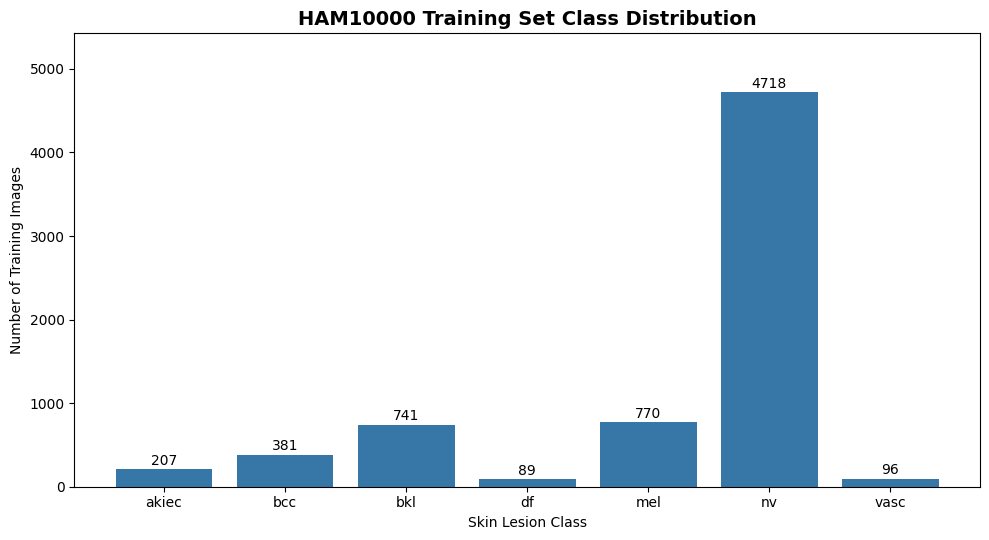

Figure Saved: /content/drive1157_cpu/MyDrive/ID1157_Research/results/training_class_distribution.png


In [ ]:

import os
import pandas as pd
import matplotlib.pyplot as plt

BASE = "/content/drive1157_cpu/MyDrive/ID1157_Research"

csv_path = os.path.join(
    BASE, "results", "class_weight_analysis.csv"
)

df = pd.read_csv(csv_path)

fig, ax = plt.subplots(figsize=(10, 5.5))

bars = ax.bar(
    df["Class"],
    df["Training Samples"],
    color="#3777A8"
)

for bar in bars:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 55,
        str(int(bar.get_height())),
        ha="center",
        fontsize=10
    )

ax.set_title(
    "HAM10000 Training Set Class Distribution",
    fontsize=14,
    fontweight="bold"
)
ax.set_xlabel("Skin Lesion Class")
ax.set_ylabel("Number of Training Images")
ax.set_ylim(0, df["Training Samples"].max() * 1.15)

plt.tight_layout()

save_path = os.path.join(
    BASE, "results",
    "training_class_distribution.png"
)

plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print("Figure Saved:", save_path)

